"DATA CLEANING AND PREPROCESSING"
 

In [10]:
# ─────────────────────────────────────────────────────
# 0. IMPORTS
# ─────────────────────────────────────────────────────
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import warnings
warnings.filterwarnings("ignore")
 

In [11]:
# ─────────────────────────────────────────────────────
# STEP 1 – LOAD RAW DATA
# ─────────────────────────────────────────────────────
print("=" * 60)
print("STEP 1 – LOAD RAW DATA")
print("=" * 60)
 
DATA_PATH = r"C:\Users\syin\Downloads\Uber_project\Datasets\final_merged_dataset5_sayed_shoaib.csv"
 
df = pd.read_csv(DATA_PATH)
 
print(f"  Raw shape       : {df.shape}")
print(f"  Columns         : {list(df.columns)}")
print(f"\n  First 3 rows:\n{df.head(3).to_string()}")
 

STEP 1 – LOAD RAW DATA
  Raw shape       : (48120, 14)
  Columns         : ['datetime', 'junction', 'Vehicles', 'ID', 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', 'event_name', 'event_type', 'is_event', 'is_holiday']

  First 3 rows:
         datetime  junction  Vehicles           ID    temp  dwpt  rhum  wdir  wspd    pres event_name event_type  is_event  is_holiday
0  1/11/2015 0:00         1        15  20151101001  18.300  17.3  94.0   0.0   0.0  1012.4        NaN        NaN         0           0
1  1/11/2015 1:00         1        13  20151101011  19.075  17.8  92.5   0.0   0.0  1012.7        NaN        NaN         0           0
2  1/11/2015 2:00         1        10  20151101021  20.625  18.8  89.5   0.0   0.0  1013.3        NaN        NaN         0           0


dataset is partially processed as weather cols 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', had two empty values alternatively
those empty values are imputed using custom interpolation (fill,bfill) so that values remain consistant(rather than sharp changes?values)

In [12]:
# ─────────────────────────────────────────────────────
# STEP 2 – CORRECT DATA TYPES
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 2 – CORRECT DATA TYPES")
print("=" * 60)
 
print("\n  Before dtype correction:")
print(df.dtypes.to_string())
 
# datetime
df["datetime"] = pd.to_datetime(df["datetime"], infer_datetime_format=True)
 
# junction, is_event, is_holiday → integers
df["junction"]   = df["junction"].astype(int)
df["is_event"]   = pd.to_numeric(df["is_event"],   errors="coerce").fillna(0).astype(int)
df["is_holiday"] = pd.to_numeric(df["is_holiday"], errors="coerce").fillna(0).astype(int)
 
# Vehicles → integer
df["Vehicles"] = pd.to_numeric(df["Vehicles"], errors="coerce")
 
# Numeric weather columns → float
weather_cols = ["temp", "dwpt", "rhum", "wdir", "wspd", "pres"]
for col in weather_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
 
# event_name, event_type → string (fill blanks with "None")
df["event_name"] = df["event_name"].fillna("None").astype(str).str.strip()
df["event_type"] = df["event_type"].fillna("None").astype(str).str.strip()
 
# ID → string (identifier, not a numeric feature)
df["ID"] = df["ID"].astype(str)
 
print("\n  After dtype correction:")
print(df.dtypes.to_string())
 
 


STEP 2 – CORRECT DATA TYPES

  Before dtype correction:
datetime       object
junction        int64
Vehicles        int64
ID              int64
temp          float64
dwpt          float64
rhum          float64
wdir          float64
wspd          float64
pres          float64
event_name     object
event_type     object
is_event        int64
is_holiday      int64

  After dtype correction:
datetime      datetime64[ns]
junction               int64
Vehicles               int64
ID                    object
temp                 float64
dwpt                 float64
rhum                 float64
wdir                 float64
wspd                 float64
pres                 float64
event_name            object
event_type            object
is_event               int64
is_holiday             int64


kay change was datetime from object to datetime64[ns], ID col from int64 to object

In [13]:
# ─────────────────────────────────────────────────────
# STEP 3 – SORT & BASIC VALIDATION
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 3 – SORT & VALIDATE")
print("=" * 60)
 
df = df.sort_values(["junction", "datetime"]).reset_index(drop=True)
 
print("\n  Rows per junction:")
print(df.groupby("junction")["Vehicles"].count().to_string())
 
print("\n  Date range per junction:")
print(df.groupby("junction")["datetime"].agg(["min", "max"]).to_string())
 
# Expected counts
expected = {1: 14592, 2: 14592, 3: 14592, 4: 4344}
for jn, exp in expected.items():
    actual = len(df[df["junction"] == jn])
    status = "OK" if actual == exp else f"WARNING: expected {exp}"
    print(f"  Junction {jn}: {actual} rows  → {status}")


STEP 3 – SORT & VALIDATE

  Rows per junction:
junction
1    14592
2    14592
3    14592
4     4344

  Date range per junction:
                min                 max
junction                               
1        2015-01-11 2017-12-06 23:00:00
2        2015-01-11 2017-12-06 23:00:00
3        2015-01-11 2017-12-06 23:00:00
4        2017-01-01 2017-12-06 23:00:00
  Junction 1: 14592 rows  → OK
  Junction 2: 14592 rows  → OK
  Junction 3: 14592 rows  → OK
  Junction 4: 4344 rows  → OK


Total count of rows for all four junction remains 48120

In [14]:
# ─────────────────────────────────────────────────────
# STEP 4 – HANDLE MISSING VALUES
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 4 – MISSING VALUES")
print("=" * 60)
 
# ── 4a. Audit all columns ──────────────────────────
missing     = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
audit = pd.DataFrame({"Missing Count": missing, "Missing %": missing_pct})
audit = audit[audit["Missing Count"] > 0].sort_values("Missing %", ascending=False)
 
if len(audit) == 0:
    print("\n  No missing values found in any column.")
else:
    print(f"\n  Columns with missing values:\n{audit.to_string()}")
 
# ── 4b. Vehicles → junction x hour median imputation ──
n_veh = df["Vehicles"].isna().sum()
if n_veh > 0:
    print(f"\n  Vehicles: {n_veh} missing → filling with junction x hour median")
    df["Vehicles"] = df.groupby(["junction", df["datetime"].dt.hour])["Vehicles"] \
                       .transform(lambda x: x.fillna(x.median()))
    df["Vehicles"] = df.groupby("junction")["Vehicles"] \
                       .transform(lambda x: x.fillna(method="ffill").fillna(method="bfill"))
    print(f"  Vehicles: {df['Vehicles'].isna().sum()} missing after treatment")
else:
    print(f"\n  Vehicles: no missing values.")
 
# ── 4c. Weather columns → linear interpolation per junction ──
for col in weather_cols:
    n_miss = df[col].isna().sum()
    if n_miss > 0:
        df[col] = df.groupby("junction")[col] \
                    .transform(lambda s: s.interpolate(method="linear")
                                          .fillna(method="ffill")
                                          .fillna(method="bfill"))
        print(f"  {col:>5}: {n_miss} missing → interpolated "
              f"({df[col].isna().sum()} remaining)")
    else:
        print(f"  {col:>5}: no missing values.")
 
# ── 4d. is_event, is_holiday → 0 if blank (no event/holiday assumption) ──
df["is_event"]   = df["is_event"].fillna(0).astype(int)
df["is_holiday"] = df["is_holiday"].fillna(0).astype(int)
 
# ── 4e. event_name / event_type → already handled in Step 2 ──
 
still_missing = df.isnull().sum()
still_missing = still_missing[still_missing > 0]
if len(still_missing) == 0:
    print("\n  All missing values resolved.")
else:
    print(f"\n  Still missing:\n{still_missing.to_string()}")


STEP 4 – MISSING VALUES

  No missing values found in any column.

  Vehicles: no missing values.
   temp: no missing values.
   dwpt: no missing values.
   rhum: no missing values.
   wdir: no missing values.
   wspd: no missing values.
   pres: no missing values.

  All missing values resolved.



STEP 5 – REMOVE DUPLICATES
  Rows before : 48,120
  Rows after  : 48,120
  Dropped     : 0 duplicate rows

STEP 5.5 – DISTRIBUTION ANALYSIS & TRANSFORMATION

  [ Skewness & Kurtosis per Junction ]
  Junction         Mean      Std     Skew     Kurt Shape
  ------------------------------------------------------------
  Junction 1        45.1     23.0     0.80     0.19   right-skewed
  Junction 2        14.3      7.4     1.29     1.78   right-skewed
  Junction 3        13.7     10.4     3.49    27.36   right-skewed
  Junction 4         7.3      3.5     1.33     4.74   right-skewed


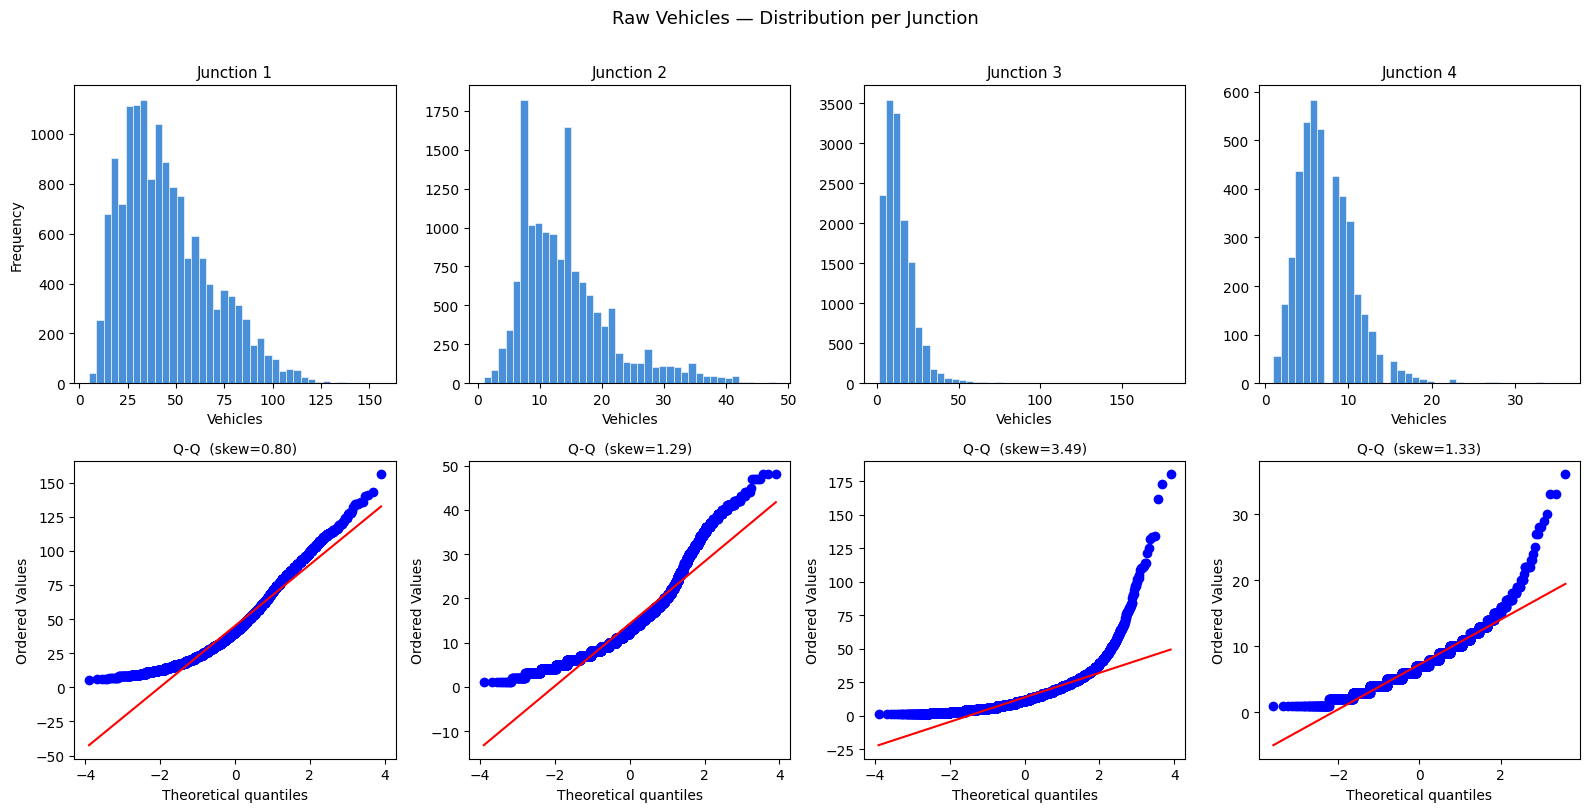


  Saved → distribution_raw.png

  [ Shapiro-Wilk normality test  (sample ≤ 5000) ]
  Junction 1: W=0.9435  p=4.2500e-40  → NOT normal
  Junction 2: W=0.8996  p=2.8509e-49  → NOT normal
  Junction 3: W=0.7675  p=1.8283e-64  → NOT normal
  Junction 4: W=0.9249  p=3.5255e-42  → NOT normal

  Applying transformation: log1p

  [ Post-transform skewness ]
  Junction        Skew before   Skew after
  ------------------------------------------
  Junction 1             0.801       -0.270
  Junction 2             1.287       -0.021
  Junction 3             3.490       -0.031
  Junction 4             1.333       -0.378

  ✓ Vehicles column is now transformed.
    Step 6 IQR capping will operate on transformed values.
    Remember to inverse-transform predictions before evaluation:
    log1p → np.expm1(x)   |   sqrt → x**2


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,event_name,event_type,is_event,is_holiday,Vehicles_raw_pretransform
0,2015-01-11 00:00:00,1,2.772589,20151101001,18.300,17.3,94.00,0.0,0.0,1012.400,None,None,0,0,15
1,2015-01-11 01:00:00,1,2.639057,20151101011,19.075,17.8,92.50,0.0,0.0,1012.700,None,None,0,0,13
2,2015-01-11 02:00:00,1,2.397895,20151101021,20.625,18.8,89.50,0.0,0.0,1013.300,None,None,0,0,10
3,2015-01-11 03:00:00,1,2.079442,20151101031,21.400,19.3,88.00,0.0,0.0,1013.600,None,None,0,0,7
4,2015-01-11 04:00:00,1,2.302585,20151101041,23.250,18.8,78.50,0.0,0.0,1013.175,None,None,0,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 19:00:00,4,2.397895,20170612194,23.350,21.4,88.75,270.0,6.6,1004.575,None,None,0,0,10
48116,2017-12-06 20:00:00,4,2.079442,20170612204,22.850,21.2,90.25,270.0,4.6,1004.125,None,None,0,0,7
48117,2017-12-06 21:00:00,4,2.197225,20170612214,22.600,21.1,91.00,270.0,3.6,1003.900,None,None,0,0,8
48118,2017-12-06 22:00:00,4,2.484907,20170612224,22.600,21.1,91.00,270.0,3.6,1003.750,None,None,0,0,11


In [15]:
# ─────────────────────────────────────────────────────
# STEP 5 – REMOVE DUPLICATES
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 5 – REMOVE DUPLICATES")
print("=" * 60)
 
before = len(df)
 
# Primary duplicate: same junction + same datetime
df.drop_duplicates(subset=["junction", "datetime"], keep="first", inplace=True)
 
# Full row duplicates
df.drop_duplicates(keep="first", inplace=True)
 
df.reset_index(drop=True, inplace=True)
dropped = before - len(df)
 
print(f"  Rows before : {before:,}")
print(f"  Rows after  : {len(df):,}")
print(f"  Dropped     : {dropped} duplicate rows")

# ─────────────────────────────────────────────────────
# STEP 5.5 – DISTRIBUTION ANALYSIS & TRANSFORMATION
# ─────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

print("\n" + "=" * 60)
print("STEP 5.5 – DISTRIBUTION ANALYSIS & TRANSFORMATION")
print("=" * 60)

# ── 1. Per-junction distribution stats ───────────────
print("\n  [ Skewness & Kurtosis per Junction ]")
print(f"  {'Junction':<12} {'Mean':>8} {'Std':>8} {'Skew':>8} {'Kurt':>8} {'Shape'}")
print("  " + "-" * 60)

for jn in sorted(df["junction"].unique()):
    v = df[df["junction"] == jn]["Vehicles"]
    sk  = v.skew()
    ku  = v.kurt()
    shape = ("right-skewed" if sk >  0.5
             else "left-skewed" if sk < -0.5
             else "~normal")
    print(f"  Junction {jn:<4} {v.mean():>8.1f} {v.std():>8.1f} {sk:>8.2f} {ku:>8.2f}   {shape}")

# ── 2. Visual: histograms + Q-Q plots (raw) ──────────
junctions = sorted(df["junction"].unique())
n = len(junctions)

fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
fig.suptitle("Raw Vehicles — Distribution per Junction", fontsize=13, y=1.01)

for i, jn in enumerate(junctions):
    v = df[df["junction"] == jn]["Vehicles"]

    # Histogram
    ax = axes[0, i] if n > 1 else axes[0]
    ax.hist(v, bins=40, color="#4A90D9", edgecolor="white", linewidth=0.4)
    ax.set_title(f"Junction {jn}", fontsize=11)
    ax.set_xlabel("Vehicles")
    ax.set_ylabel("Frequency" if i == 0 else "")

    # Q-Q plot
    ax2 = axes[1, i] if n > 1 else axes[1]
    stats.probplot(v, dist="norm", plot=ax2)
    ax2.set_title(f"Q-Q  (skew={v.skew():.2f})", fontsize=10)

plt.tight_layout()
plt.savefig("distribution_raw.png", dpi=150, bbox_inches="tight")
plt.show()
print("\n  Saved → distribution_raw.png")

# ── 3. Normality test (Shapiro-Wilk on sample) ───────
print("\n  [ Shapiro-Wilk normality test  (sample ≤ 5000) ]")
for jn in sorted(df["junction"].unique()):
    v = df[df["junction"] == jn]["Vehicles"].dropna()
    sample = v.sample(min(5000, len(v)), random_state=42)
    stat, p = stats.shapiro(sample)
    result = "NOT normal" if p < 0.05 else "~normal"
    print(f"  Junction {jn}: W={stat:.4f}  p={p:.4e}  → {result}")

# ── 4. Decide & apply transformation ─────────────────
#
#  Common choices for right-skewed count data:
#    • log1p  : np.log1p(x)   – handles zeros, very common for counts
#    • sqrt   : np.sqrt(x)    – gentler, good for moderate skew
#    • box-cox: only for strictly positive data (no zeros)
#
#  Change TRANSFORM below to suit your data.
#  After transformation, Step 6 IQR capping will be
#  more symmetric and the bounds will be meaningful.

TRANSFORM = "log1p"   # ← adjust: "log1p" | "sqrt" | "none"

print(f"\n  Applying transformation: {TRANSFORM}")

df["Vehicles_raw_pretransform"] = df["Vehicles"].copy()

if TRANSFORM == "log1p":
    df["Vehicles"] = np.log1p(df["Vehicles"])
elif TRANSFORM == "sqrt":
    df["Vehicles"] = np.sqrt(df["Vehicles"])
elif TRANSFORM == "none":
    print("  No transformation applied.")
else:
    raise ValueError(f"Unknown transform: {TRANSFORM}")

# ── 5. Post-transform skewness check ─────────────────
if TRANSFORM != "none":
    print("\n  [ Post-transform skewness ]")
    print(f"  {'Junction':<12} {'Skew before':>14} {'Skew after':>12}")
    print("  " + "-" * 42)
    for jn in sorted(df["junction"].unique()):
        raw  = df[df["junction"] == jn]["Vehicles_raw_pretransform"].skew()
        post = df[df["junction"] == jn]["Vehicles"].skew()
        print(f"  Junction {jn:<4} {raw:>14.3f} {post:>12.3f}")

print("\n  ✓ Vehicles column is now transformed.")
print("    Step 6 IQR capping will operate on transformed values.")
print("    Remember to inverse-transform predictions before evaluation:\n"
      "    log1p → np.expm1(x)   |   sqrt → x**2")
df

In [8]:
# ─────────────────────────────────────────────────────
# STEP 6 – OUTLIER TREATMENT (IQR Capping per Junction)
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 6 – OUTLIER TREATMENT")
print("=" * 60)
 
df["Vehicles_raw"] = df["Vehicles"].copy()
 
def iqr_cap(series):
    q1  = series.quantile(0.25)
    q3  = series.quantile(0.75)
    iqr = q3 - q1
    return series.clip(lower=q1 - 1.5 * iqr, upper=q3 + 1.5 * iqr)
 
df["Vehicles"] = df.groupby("junction")["Vehicles"].transform(iqr_cap)
n_capped = (df["Vehicles_raw"] != df["Vehicles"]).sum()
 
print(f"  Total values capped: {n_capped} ({n_capped/len(df)*100:.2f}%)")
for jn in sorted(df["junction"].unique()):
    sub  = df[df["junction"] == jn]
    diff = (sub["Vehicles_raw"] != sub["Vehicles"]).sum()
    q1   = sub["Vehicles_raw"].quantile(0.25)
    q3   = sub["Vehicles_raw"].quantile(0.75)
    iqr  = q3 - q1
    lo   = round(q1 - 1.5 * iqr, 1)
    hi   = round(q3 + 1.5 * iqr, 1)
    print(f"    Junction {jn}: IQR bounds [{lo}, {hi}]  →  {diff} values capped")
 


STEP 6 – OUTLIER TREATMENT
  Total values capped: 376 (0.78%)
    Junction 1: IQR bounds [2.2, 5.2]  →  13 values capped
    Junction 2: IQR bounds [1.4, 3.8]  →  146 values capped
    Junction 3: IQR bounds [0.8, 4.2]  →  139 values capped
    Junction 4: IQR bounds [1.0, 3.1]  →  78 values capped


Most of the capping was done to junction two -> 146 values capped

In [21]:
# ─────────────────────────────────────────────────────
# STEP 7 – TEMPORAL FEATURE EXTRACTION
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 7 – TEMPORAL FEATURE EXTRACTION")
print("=" * 60)
 
df["year"]       = df["datetime"].dt.year
df["month"]      = df["datetime"].dt.month
df["day"]        = df["datetime"].dt.day
df["hour"]       = df["datetime"].dt.hour
df["dayofweek"]  = df["datetime"].dt.dayofweek        # 0=Monday
df["dayofyear"]  = df["datetime"].dt.dayofyear
df["weekofyear"] = df["datetime"].dt.isocalendar().week.astype(int)
df["quarter"]    = df["datetime"].dt.quarter
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int)
 
bins   = [-1, 5, 11, 17, 20, 23]
labels = ["Night(0-5)", "Morning(6-11)", "Afternoon(12-17)",
          "Evening(18-20)", "Night(21-23)"]
df["time_of_day"] = pd.cut(df["hour"], bins=bins, labels=labels)
 
print("  Added: year, month, day, hour, dayofweek, dayofyear,")
print("         weekofyear, quarter, is_weekend, time_of_day")
df 


STEP 7 – TEMPORAL FEATURE EXTRACTION
  Added: year, month, day, hour, dayofweek, dayofyear,
         weekofyear, quarter, is_weekend, time_of_day


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,year,month,day,hour,dayofweek,dayofyear,weekofyear,quarter,is_weekend,time_of_day
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.00,0.0,0.0,1012.400,...,2015,1,11,0,6,11,2,1,1,Night(0-5)
1,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.50,0.0,0.0,1012.700,...,2015,1,11,1,6,11,2,1,1,Night(0-5)
2,2015-01-11 02:00:00,1,10.0,20151101021,20.625,18.8,89.50,0.0,0.0,1013.300,...,2015,1,11,2,6,11,2,1,1,Night(0-5)
3,2015-01-11 03:00:00,1,7.0,20151101031,21.400,19.3,88.00,0.0,0.0,1013.600,...,2015,1,11,3,6,11,2,1,1,Night(0-5)
4,2015-01-11 04:00:00,1,9.0,20151101041,23.250,18.8,78.50,0.0,0.0,1013.175,...,2015,1,11,4,6,11,2,1,1,Night(0-5)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 19:00:00,4,10.0,20170612194,23.350,21.4,88.75,270.0,6.6,1004.575,...,2017,12,6,19,2,340,49,4,0,Evening(18-20)
48116,2017-12-06 20:00:00,4,7.0,20170612204,22.850,21.2,90.25,270.0,4.6,1004.125,...,2017,12,6,20,2,340,49,4,0,Evening(18-20)
48117,2017-12-06 21:00:00,4,8.0,20170612214,22.600,21.1,91.00,270.0,3.6,1003.900,...,2017,12,6,21,2,340,49,4,0,Night(21-23)
48118,2017-12-06 22:00:00,4,11.0,20170612224,22.600,21.1,91.00,270.0,3.6,1003.750,...,2017,12,6,22,2,340,49,4,0,Night(21-23)


following cols : year, month, day, hour, dayofweek, dayofyear,
                 weekofyear, quarter,
are  extracted from 'datetime' col itself

In [22]:
# ─────────────────────────────────────────────────────
# STEP 8 – NORMALIZATION & STANDARDIZATION
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 8 – NORMALIZE & STANDARDIZE")
print("=" * 60)
 
# ── 8a. Train / Test split (before any scaling — prevents leakage) ──
cutoff   = df["datetime"].max() - pd.DateOffset(months=2)
train_df = df[df["datetime"] <= cutoff].copy()
test_df  = df[df["datetime"] >  cutoff].copy()
 
print(f"\n  Train : {len(train_df):,} rows  "
      f"({train_df['datetime'].min().date()} → {train_df['datetime'].max().date()})")
print(f"  Test  : {len(test_df):,} rows  "
      f"({test_df['datetime'].min().date()} → {test_df['datetime'].max().date()})")
 
# ── 8b. StandardScaler — for ML model features ──────
#        Purpose : equalise scales of hour, temp, wspd, pres etc.
#        Rule    : fit on train only, apply same transform to test
MODEL_FEATURES = [
    "hour", "dayofweek", "month", "year", "quarter",
    "is_weekend", "is_event", "is_holiday",
    "temp", "dwpt", "rhum", "wdir", "wspd", "pres"
]
MODEL_FEATURES = [c for c in MODEL_FEATURES if c in df.columns]
 
std_scaler  = StandardScaler()
X_train     = train_df[MODEL_FEATURES].fillna(0)
X_test      = test_df[MODEL_FEATURES].fillna(0)
 
X_train_std = pd.DataFrame(
    std_scaler.fit_transform(X_train),   # fit + transform on train
    columns=MODEL_FEATURES,
    index=X_train.index
)
X_test_std = pd.DataFrame(
    std_scaler.transform(X_test),        # transform only on test
    columns=MODEL_FEATURES,
    index=X_test.index
)
 
print(f"\n  StandardScaler (model features) — fit on train only:")
print(f"  X_train_std : {X_train_std.shape}  mean≈0, std≈1")
print(f"  X_test_std  : {X_test_std.shape}")
print("\n  Feature means after scaling (train, should be ~0.00):")
for col in MODEL_FEATURES:
    print(f"    {col:<12}: mean={X_train_std[col].mean():+.4f}  "
          f"std={X_train_std[col].std():.4f}")
 
# ── 8c. MinMaxScaler — cross-junction & cross-period comparison ──
#        Purpose : Junction 1 peaks at ~20, Junction 4 peaks at ~80.
#                  Normalizing each junction separately puts both on
#                  0–1 so their daily/hourly shapes are comparable.
mm_scaler = MinMaxScaler()
 
df["Vehicles_norm"] = df.groupby("junction")["Vehicles"] \
    .transform(lambda x: mm_scaler.fit_transform(
        x.values.reshape(-1, 1)).flatten())
 
print(f"\n  MinMaxScaler (Vehicles per junction, for visualization):")
for jn in sorted(df["junction"].unique()):
    sub = df[df["junction"] == jn]
    print(f"    Junction {jn}: raw [{sub['Vehicles'].min():.0f}–"
          f"{sub['Vehicles'].max():.0f}]"
          f"  →  norm [{sub['Vehicles_norm'].min():.2f}–"
          f"{sub['Vehicles_norm'].max():.2f}]")
 
# ── 8d. Normalize weather features per junction ──────
#        Purpose : compare temperature/humidity trends across
#                  different junctions and time periods fairly
weather_norm_cols = ["temp", "rhum", "wspd", "pres"]
for col in weather_norm_cols:
    df[f"{col}_norm"] = df.groupby("junction")[col] \
        .transform(lambda x: mm_scaler.fit_transform(
            x.values.reshape(-1, 1)).flatten())
 
print(f"\n  MinMaxScaler applied to weather columns per junction:")
print(f"  {[c+'_norm' for c in weather_norm_cols]}")
 


STEP 8 – NORMALIZE & STANDARDIZE

  Train : 46,968 rows  (2015-01-11 → 2017-10-06)
  Test  : 1,152 rows  (2017-11-01 → 2017-12-06)

  StandardScaler (model features) — fit on train only:
  X_train_std : (46968, 14)  mean≈0, std≈1
  X_test_std  : (1152, 14)

  Feature means after scaling (train, should be ~0.00):
    hour        : mean=-0.0000  std=1.0000
    dayofweek   : mean=+0.0000  std=1.0000
    month       : mean=-0.0000  std=1.0000
    year        : mean=-0.0000  std=1.0000
    quarter     : mean=+0.0000  std=1.0000
    is_weekend  : mean=-0.0000  std=1.0000
    is_event    : mean=-0.0000  std=1.0000
    is_holiday  : mean=+0.0000  std=1.0000
    temp        : mean=-0.0000  std=1.0000
    dwpt        : mean=-0.0000  std=1.0000
    rhum        : mean=+0.0000  std=1.0000
    wdir        : mean=+0.0000  std=1.0000
    wspd        : mean=-0.0000  std=1.0000
    pres        : mean=-0.0000  std=1.0000

  MinMaxScaler (Vehicles per junction, for visualization):
    Junction 1: raw [5–

Current split — last 2 months as test
Junction	Total rows	Train (to Apr 2017)	Test (May–Jun 2017)	Test %
J1	14,592	13,128	1,464	10%
J2	14,592	13,128	1,464	10%
J3	14,592	13,128	1,464	10%
J4	4,344	2,880	1,464	34%
Total	48,120	42,264	5,856	12.2%
Train 88%
Test 12%
imp : 'Splitting is done before scaling to prevent leakage'

In [23]:
# ─────────────────────────────────────────────────────
# STEP 9 – BEFORE vs AFTER SUMMARY
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 9 – SUMMARY STATISTICS")
print("=" * 60)
 
print("\n  Raw vs Cleaned Vehicles per junction:")
compare = df.groupby("junction").agg(
    Raw_Mean   =("Vehicles_raw", "mean"),
    Clean_Mean =("Vehicles",     "mean"),
    Raw_Max    =("Vehicles_raw", "max"),
    Clean_Max  =("Vehicles",     "max"),
    Norm_Min   =("Vehicles_norm","min"),
    Norm_Max   =("Vehicles_norm","max"),
).round(2)
print(compare.to_string())
 
print("\n  Standardized features (train set) — all means ~0, stds ~1:")
print(X_train_std.agg(["mean","std"]).round(3).to_string())
 
 


STEP 9 – SUMMARY STATISTICS

  Raw vs Cleaned Vehicles per junction:
          Raw_Mean  Clean_Mean  Raw_Max  Clean_Max  Norm_Min  Norm_Max
junction                                                              
1            45.05       44.96      156      107.0       0.0       1.0
2            14.25       13.94       48       29.0       0.0       1.0
3            13.69       13.17      180       34.5       0.0       1.0
4             7.25        7.16       36       15.0       0.0       1.0

  Standardized features (train set) — all means ~0, stds ~1:
      hour  dayofweek  month  year  quarter  is_weekend  is_event  is_holiday  temp  dwpt  rhum  wdir  wspd  pres
mean  -0.0        0.0   -0.0  -0.0      0.0        -0.0      -0.0         0.0  -0.0  -0.0   0.0   0.0  -0.0  -0.0
std    1.0        1.0    1.0   1.0      1.0         1.0       1.0         1.0   1.0   1.0   1.0   1.0   1.0   1.0


In [26]:
# ─────────────────────────────────────────────────────
# STEP 10 – SAVE ALL OUTPUTS
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("STEP 10 – SAVE OUTPUTS")
print("=" * 60)
 
OUT = r"C:\Users\syin\Downloads\Uber_project\Datasets"
 
df.to_csv(            OUT + r"\cleaned_traffic_data.csv",  index=False)
X_train_std.to_csv(   OUT + r"\X_train_scaled.csv",        index=False)
X_test_std.to_csv(    OUT + r"\X_test_scaled.csv",         index=False)
train_df["Vehicles"].to_csv(OUT + r"\y_train.csv",         index=False)
test_df["Vehicles"].to_csv( OUT + r"\y_test.csv",          index=False)
 
print(f"  [Saved] cleaned_traffic_data.csv  "
      f"({df.shape[0]:,} rows x {df.shape[1]} cols)")
print("  [Saved] X_train_scaled.csv  |  X_test_scaled.csv")
print("  [Saved] y_train.csv  |  y_test.csv")


STEP 10 – SAVE OUTPUTS
  [Saved] cleaned_traffic_data.csv  (48,120 rows x 30 cols)
  [Saved] X_train_scaled.csv  |  X_test_scaled.csv
  [Saved] y_train.csv  |  y_test.csv


In [27]:
# ─────────────────────────────────────────────────────
# STEP 11 – FINAL CHECKLIST
# ─────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("CLEANING & PREPROCESSING COMPLETE")
print("=" * 60)
print(f"""
  Rows after cleaning         : {len(df):,}
  Columns in output           : {df.shape[1]}
  Missing values remaining    : {df.isnull().sum().sum()}
  Duplicate rows removed      : {dropped}
  Outlier values capped       : {n_capped}
 
  Columns added
  ─────────────────────────────────────────────────────
  Temporal   : year, month, day, hour, dayofweek,
               dayofyear, weekofyear, quarter,
               is_weekend, time_of_day
  Scaling    : Vehicles_norm      (MinMax per junction)
               Vehicles_raw       (original before cap)
               temp_norm, rhum_norm, wspd_norm, pres_norm
 
  Output files
  ─────────────────────────────────────────────────────
  cleaned_traffic_data.csv  ← full cleaned dataset
  X_train_scaled.csv        ← standardized train features
  X_test_scaled.csv         ← standardized test features
  y_train.csv / y_test.csv  ← target (Vehicles)
""")


CLEANING & PREPROCESSING COMPLETE

  Rows after cleaning         : 48,120
  Columns in output           : 30
  Missing values remaining    : 0
  Duplicate rows removed      : 0
  Outlier values capped       : 1558
 
  Columns added
  ─────────────────────────────────────────────────────
  Temporal   : year, month, day, hour, dayofweek,
               dayofyear, weekofyear, quarter,
               is_weekend, time_of_day
  Scaling    : Vehicles_norm      (MinMax per junction)
               Vehicles_raw       (original before cap)
               temp_norm, rhum_norm, wspd_norm, pres_norm
 
  Output files
  ─────────────────────────────────────────────────────
  cleaned_traffic_data.csv  ← full cleaned dataset
  X_train_scaled.csv        ← standardized train features
  X_test_scaled.csv         ← standardized test features
  y_train.csv / y_test.csv  ← target (Vehicles)



"""
Feature Engineering and Selection for Traffic Volume Prediction
==============================================================
This script builds on the cleaned_traffic_data and performs:
  1. Time-based feature generation
  2. Lag & rolling-window features
  3. Binary indicators (weekend, special events)
  4. Feature importance evaluation (correlation + Random Forest)
  5. Final feature selection
"""

"FEATURE ENGINEERING AND SELECTION"


In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.inspection import permutation_importance
import warnings
warnings.filterwarnings("ignore")

In [47]:
# ─────────────────────────────────────────────
# 0.  LOAD DATA
# ─────────────────────────────────────────────
# Replace with actual file path if needed
df = pd.read_csv(r"C:\Users\syin\Downloads\Uber_project\Datasets\cleaned_traffic_data.csv")
 
# Ensure datetime is parsed correctly
if "datetime" in df.columns:
    df["datetime"] = pd.to_datetime(df["datetime"])
    df = df.sort_values("datetime").reset_index(drop=True)
 
print(f"Dataset shape: {df.shape}")
print(df.dtypes.to_string())
 

Dataset shape: (48120, 30)
datetime         datetime64[ns]
junction                  int64
Vehicles                float64
ID                        int64
temp                    float64
dwpt                    float64
rhum                    float64
wdir                    float64
wspd                    float64
pres                    float64
event_name               object
event_type               object
is_event                  int64
is_holiday                int64
Vehicles_raw              int64
year                      int64
month                     int64
day                       int64
hour                      int64
dayofweek                 int64
dayofyear                 int64
weekofyear                int64
quarter                   int64
is_weekend                int64
time_of_day              object
Vehicles_norm           float64
temp_norm               float64
rhum_norm               float64
wspd_norm               float64
pres_norm               float64


the dataset used was generated from above data cleaning and prerocessing .

In [48]:
# ─────────────────────────────────────────────
# 1.  TIME-BASED FEATURES
# ─────────────────────────────────────────────
print("\n[1] Generating time-based features …")
 
df["hour"]        = df["datetime"].dt.hour
df["day_of_week"] = df["datetime"].dt.dayofweek          # 0 = Monday
df["day_of_month"]= df["datetime"].dt.day
df["month"]       = df["datetime"].dt.month
df["year"]        = df["datetime"].dt.year
df["week_of_year"]= df["datetime"].dt.isocalendar().week.astype(int)
df["quarter"]     = df["datetime"].dt.quarter
 
# Cyclic encoding  – preserves the circular nature of time
for col, period in [("hour", 24), ("day_of_week", 7), ("month", 12)]:
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / period)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / period)
 
# Rush-hour flag  (7-9 AM and 5-7 PM)
df["is_rush_hour"] = df["hour"].apply(
    lambda h: 1 if (7 <= h <= 9) or (17 <= h <= 19) else 0
)
 
# Time-of-day bucket
def time_bucket(h):
    if   0  <= h <  6:  return "Night"
    elif 6  <= h < 12:  return "Morning"
    elif 12 <= h < 18:  return "Afternoon"
    else:               return "Evening"
 
df["time_of_day"] = df["hour"].apply(time_bucket)
 
print("  Time-based features added:", [
    "hour","day_of_week","day_of_month","month","year",
    "week_of_year","quarter",
    "hour_sin","hour_cos","day_of_week_sin","day_of_week_cos",
    "month_sin","month_cos","is_rush_hour","time_of_day"
])
df 


[1] Generating time-based features …
  Time-based features added: ['hour', 'day_of_week', 'day_of_month', 'month', 'year', 'week_of_year', 'quarter', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_rush_hour', 'time_of_day']


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,day_of_week,day_of_month,week_of_year,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,is_rush_hour
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,6,11,2,0.000000,1.000000,-0.781831,0.623490,5.000000e-01,0.866025,0
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,6,11,2,0.000000,1.000000,-0.781831,0.623490,5.000000e-01,0.866025,0
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,6,11,2,0.000000,1.000000,-0.781831,0.623490,5.000000e-01,0.866025,0
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,6,11,2,0.258819,0.965926,-0.781831,0.623490,5.000000e-01,0.866025,0
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,6,11,2,0.258819,0.965926,-0.781831,0.623490,5.000000e-01,0.866025,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,2,6,49,-0.500000,0.866025,0.974928,-0.222521,-2.449294e-16,1.000000,0
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,2,6,49,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000,0
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,2,6,49,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000,0
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,2,6,49,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000,0


In [49]:
# ─────────────────────────────────────────────
# 2.  BINARY INDICATORS
# ─────────────────────────────────────────────
print("\n[2] Creating binary indicators …")
 
# Weekend flag
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
 
# Special-event flag  (use existing column if present, else default to 0)
if "is_event" in df.columns:
    df["is_special_event"] = df["is_event"].astype(int)
elif "event_name" in df.columns:
    df["is_special_event"] = (df["event_name"].notna() &
                               (df["event_name"] != "None")).astype(int)
else:
    df["is_special_event"] = 0
 
# Holiday flag  (use existing column if present)
if "is_holiday" in df.columns:
    df["is_holiday"] = df["is_holiday"].astype(int)
else:
    df["is_holiday"] = 0
 
# Workday flag  (Mon–Fri, non-holiday, non-event)
df["is_workday"] = (
    (df["is_weekend"]       == 0) &
    (df["is_holiday"]       == 0) &
    (df["is_special_event"] == 0)
).astype(int)
 
print("  Binary indicators added: is_weekend, is_special_event, is_holiday, is_workday")
df 


[2] Creating binary indicators …
  Binary indicators added: is_weekend, is_special_event, is_holiday, is_workday


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,week_of_year,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,is_rush_hour,is_special_event,is_workday
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,2,0.000000,1.000000,-0.781831,0.623490,5.000000e-01,0.866025,0,0,0
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,2,0.000000,1.000000,-0.781831,0.623490,5.000000e-01,0.866025,0,0,0
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,2,0.000000,1.000000,-0.781831,0.623490,5.000000e-01,0.866025,0,0,0
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,2,0.258819,0.965926,-0.781831,0.623490,5.000000e-01,0.866025,0,0,0
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,2,0.258819,0.965926,-0.781831,0.623490,5.000000e-01,0.866025,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,49,-0.500000,0.866025,0.974928,-0.222521,-2.449294e-16,1.000000,0,0,1
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,49,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000,0,0,1
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,49,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000,0,0,1
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,49,-0.258819,0.965926,0.974928,-0.222521,-2.449294e-16,1.000000,0,0,1


In [50]:
# ─────────────────────────────────────────────
# 3.  LAG & ROLLING-WINDOW FEATURES
# ─────────────────────────────────────────────
print("\n[3] Creating lag and rolling-window features …")
 
TARGET = "Vehicles"   # <-- change if your target column has a different name
 
if TARGET in df.columns:
    # Lag features (past 1 h, 2 h, 3 h, 6 h, 12 h, 24 h, 168 h = 1 week)
    for lag in [1, 2, 3, 6, 12, 24, 168]:
        df[f"lag_{lag}h"] = df[TARGET].shift(lag)
 
    # Rolling statistics  (3 h, 6 h, 24 h windows)
    for window in [3, 6, 24]:
        df[f"rolling_mean_{window}h"] = (
            df[TARGET].shift(1).rolling(window).mean()
        )
        df[f"rolling_std_{window}h"] = (
            df[TARGET].shift(1).rolling(window).std()
        )
        df[f"rolling_max_{window}h"] = (
            df[TARGET].shift(1).rolling(window).max()
        )
        df[f"rolling_min_{window}h"] = (
            df[TARGET].shift(1).rolling(window).min()
        )
 
    # Exponentially weighted moving average
    df["ewma_12h"] = df[TARGET].shift(1).ewm(span=12).mean()
    df["ewma_24h"] = df[TARGET].shift(1).ewm(span=24).mean()
 
    print(f"  Lag + rolling features added for target '{TARGET}'.")
else:
    print(f"  WARNING: target column '{TARGET}' not found – skipping lag features.")
df


[3] Creating lag and rolling-window features …
  Lag + rolling features added for target 'Vehicles'.


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,rolling_mean_6h,rolling_std_6h,rolling_max_6h,rolling_min_6h,rolling_mean_24h,rolling_std_24h,rolling_max_24h,rolling_min_24h,ewma_12h,ewma_24h
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.000000,15.000000
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.125000,10.312500
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.685912,9.838057
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.838075,9.037496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,32.000000,31.622777,94.0,8.0,40.500000,38.511433,107.0,7.0,42.467395,41.440056
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,33.000000,30.796104,94.0,11.0,40.458333,38.540751,107.0,7.0,38.087796,39.244852
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,44.666667,37.802998,94.0,11.0,39.791667,37.463001,107.0,7.0,46.228135,43.385264
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,42.666667,39.093051,94.0,11.0,39.583333,37.579963,107.0,7.0,41.731499,41.274443


In [51]:
# ─────────────────────────────────────────────
# 4.  LAG & ROLLING-WINDOW FEATURES
# ─────────────────────────────────────────────
print("\n[3] Creating lag and rolling-window features …")

TARGET = "Vehicles"   # <-- change if your target column has a different name

if TARGET in df.columns:
    # Lag features (past 1 h, 2 h, 3 h, 6 h, 12 h, 24 h, 168 h = 1 week)
    for lag in [1, 2, 3, 6, 12, 24, 168]:
        df[f"lag_{lag}h"] = df[TARGET].shift(lag)

    # Rolling statistics  (3 h, 6 h, 24 h windows)
    for window in [3, 6, 24]:
        df[f"rolling_mean_{window}h"] = (
            df[TARGET].shift(1).rolling(window).mean()
        )
        df[f"rolling_std_{window}h"] = (
            df[TARGET].shift(1).rolling(window).std()
        )
        df[f"rolling_max_{window}h"] = (
            df[TARGET].shift(1).rolling(window).max()
        )
        df[f"rolling_min_{window}h"] = (
            df[TARGET].shift(1).rolling(window).min()
        )

    # Exponentially weighted moving average
    df["ewma_12h"] = df[TARGET].shift(1).ewm(span=12).mean()
    df["ewma_24h"] = df[TARGET].shift(1).ewm(span=24).mean()

    print(f"  Lag + rolling features added for target '{TARGET}'.")
else:
    print(f"  WARNING: target column '{TARGET}' not found – skipping lag features.")


# ─────────────────────────────────────────────
# 4.  SAVE DATASET
# ─────────────────────────────────────────────
import os

print("\n[4] Saving engineered dataset …")

SAVE_DIR = r"C:\Users\syin\Downloads\Uber_project\Datasets"
os.makedirs(SAVE_DIR, exist_ok=True)

# ── Save as CSV ──────────────────────────────
csv_path = os.path.join(SAVE_DIR, "uber_features_engineered_lag.csv")
df.to_csv(csv_path, index=True)
print(f"  ✔ CSV saved  →  {csv_path}")

# ── Save as Parquet (faster reads, smaller file) ─────────────────────────────
try:
    parquet_path = os.path.join(SAVE_DIR, "uber_features_engineered.parquet")
    df.to_parquet(parquet_path, index=True, engine="pyarrow", compression="snappy")
    print(f"  ✔ Parquet saved  →  {parquet_path}")
except ImportError:
    print("  ℹ  pyarrow not installed – skipping Parquet save.")
    print("     Run:  pip install pyarrow   to enable Parquet support.")

# ── Quick sanity check ───────────────────────
print(f"\n  Dataset shape after feature engineering : {df.shape}")
print(f"  Columns ({len(df.columns)}) :\n  {list(df.columns)}")
print(f"  NaN counts (first 10 cols) :\n{df.iloc[:, :10].isna().sum().to_string()}")
print("\n  [Done] All files saved successfully.")
df


[3] Creating lag and rolling-window features …
  Lag + rolling features added for target 'Vehicles'.

[4] Saving engineered dataset …
  ✔ CSV saved  →  C:\Users\syin\Downloads\Uber_project\Datasets\uber_features_engineered_lag.csv
  ℹ  pyarrow not installed – skipping Parquet save.
     Run:  pip install pyarrow   to enable Parquet support.

  Dataset shape after feature engineering : (48120, 63)
  Columns (63) :
  ['datetime', 'junction', 'Vehicles', 'ID', 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', 'event_name', 'event_type', 'is_event', 'is_holiday', 'Vehicles_raw', 'year', 'month', 'day', 'hour', 'dayofweek', 'dayofyear', 'weekofyear', 'quarter', 'is_weekend', 'time_of_day', 'Vehicles_norm', 'temp_norm', 'rhum_norm', 'wspd_norm', 'pres_norm', 'day_of_week', 'day_of_month', 'week_of_year', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_rush_hour', 'is_special_event', 'is_workday', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'l

,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,rolling_mean_6h,rolling_std_6h,rolling_max_6h,rolling_min_6h,rolling_mean_24h,rolling_std_24h,rolling_max_24h,rolling_min_24h,ewma_12h,ewma_24h
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.000000,15.000000
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.125000,10.312500
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.685912,9.838057
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.838075,9.037496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,32.000000,31.622777,94.0,8.0,40.500000,38.511433,107.0,7.0,42.467395,41.440056
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,33.000000,30.796104,94.0,11.0,40.458333,38.540751,107.0,7.0,38.087796,39.244852
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,44.666667,37.802998,94.0,11.0,39.791667,37.463001,107.0,7.0,46.228135,43.385264
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,42.666667,39.093051,94.0,11.0,39.583333,37.579963,107.0,7.0,41.731499,41.274443


In [52]:
# ─────────────────────────────────────────────
# 5.  HANDLE ALL NaN — LAGS, ROLLING & EVENTS
# ─────────────────────────────────────────────
print("\n[4] Handling all NaN values …")

import numpy as np

# ── 4a. LAG COLUMNS → fill with TARGET value ──
lag_cols = [c for c in df.columns if c.startswith("lag_")]
for col in lag_cols:
    df[col] = df[col].fillna(df[TARGET])
print(f"  ✔ Lag columns ({len(lag_cols)}): filled with '{TARGET}' value")

# ── 4b. ROLLING STAT COLUMNS → fill with TARGET value first, then bfill ──
rolling_cols = [c for c in df.columns if c.startswith("rolling_")]
for col in rolling_cols:
    df[col] = df[col].fillna(df[TARGET])   # cold-start rows
df[rolling_cols] = df[rolling_cols].bfill() # any residual
print(f"  ✔ Rolling columns ({len(rolling_cols)}): filled with '{TARGET}' + bfill")

# ── 4c. EWMA COLUMNS → bfill (ewma rarely has NaN except row 0) ──
ewma_cols = [c for c in df.columns if c.startswith("ewma_")]
df[ewma_cols] = df[ewma_cols].bfill()
print(f"  ✔ EWMA columns ({len(ewma_cols)}): backfilled")

# ── 4d. EVENT COLUMNS → fill with "None" string ──
event_cols = ["event_name", "event_type"]
for col in event_cols:
    if col in df.columns:
        df[col] = df[col].replace(r'^\s*$', np.nan, regex=True)  # empty string → NaN
        df[col] = df[col].fillna("None")                          # NaN → "None"
        print(f"  ✔ '{col}': empty/NaN → filled with string 'None'")
    else:
        print(f"  ℹ  '{col}' not found in df – skipping")

# ── 4e. FINAL CHECK ──────────────────────────
df_fe = df.copy()

total_nan = df_fe.isna().sum().sum()
nan_by_col = df_fe.isna().sum()
nan_cols   = nan_by_col[nan_by_col > 0]

if total_nan == 0:
    print(f"\n   No NaN remaining. Shape preserved: {df_fe.shape}")
else:
    print(f"\n  ⚠  {total_nan} NaN still remaining in these columns:")
    print(nan_cols.to_string())
    print(f"\n  Shape: {df_fe.shape}")
df    


[4] Handling all NaN values …
  ✔ Lag columns (7): filled with 'Vehicles' value
  ✔ Rolling columns (12): filled with 'Vehicles' + bfill
  ✔ EWMA columns (2): backfilled
  ✔ 'event_name': empty/NaN → filled with string 'None'
  ✔ 'event_type': empty/NaN → filled with string 'None'

  ✅ No NaN remaining. Shape preserved: (48120, 63)


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,rolling_mean_6h,rolling_std_6h,rolling_max_6h,rolling_min_6h,rolling_mean_24h,rolling_std_24h,rolling_max_24h,rolling_min_24h,ewma_12h,ewma_24h
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,15.000000,15.000000,15.0,15.0,15.000000,15.000000,15.0,15.0,15.000000,15.000000
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,6.000000,6.000000,6.0,6.0,6.000000,6.000000,6.0,6.0,15.000000,15.000000
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,9.000000,9.000000,9.0,9.0,9.000000,9.000000,9.0,9.0,10.125000,10.312500
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,7.000000,7.000000,7.0,7.0,7.000000,7.000000,7.0,7.0,9.685912,9.838057
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,13.000000,13.000000,13.0,13.0,13.000000,13.000000,13.0,13.0,8.838075,9.037496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,32.000000,31.622777,94.0,8.0,40.500000,38.511433,107.0,7.0,42.467395,41.440056
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,33.000000,30.796104,94.0,11.0,40.458333,38.540751,107.0,7.0,38.087796,39.244852
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,44.666667,37.802998,94.0,11.0,39.791667,37.463001,107.0,7.0,46.228135,43.385264
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,42.666667,39.093051,94.0,11.0,39.583333,37.579963,107.0,7.0,41.731499,41.274443


LAG COLUMNS → filled with TARGET value
ROLLING STAT COLUMNS → filled with TARGET value first, then bfill

In [53]:
import pandas as pd
import numpy as np
import os

# ── Reload dataset ──
df = pd.read_csv(r"C:\Users\syin\Downloads\Uber_project\Datasets\cleaned_traffic_data.csv")
df["datetime"] = pd.to_datetime(df["datetime"], format="mixed", dayfirst=True)
df = df.sort_values(["junction", "datetime"]).reset_index(drop=True)

TARGET = "Vehicles"

print(f"Loaded: {df.shape}")
print(f"Columns: {list(df.columns)}")

# ── 4a. LAG COLUMNS → fill with TARGET value ──
lag_cols = [c for c in df.columns if c.startswith("lag_")]
for col in lag_cols:
    df[col] = df[col].fillna(df[TARGET])
print(f"  ✔ Lag columns ({len(lag_cols)}): filled with '{TARGET}' value")

# ── 4b. ROLLING STAT COLUMNS → fill with TARGET value first, then bfill ──
rolling_cols = [c for c in df.columns if c.startswith("rolling_")]
for col in rolling_cols:
    df[col] = df[col].fillna(df[TARGET])
df[rolling_cols] = df[rolling_cols].bfill()
print(f"  ✔ Rolling columns ({len(rolling_cols)}): filled with '{TARGET}' + bfill")

# ── 4c. EWMA COLUMNS → bfill ──
ewma_cols = [c for c in df.columns if c.startswith("ewma_")]
df[ewma_cols] = df[ewma_cols].bfill()
print(f"  ✔ EWMA columns ({len(ewma_cols)}): backfilled")

# ── 4d. EVENT COLUMNS → fill with "None" string ──
event_cols = ["event_name", "event_type"]
for col in event_cols:
    if col in df.columns:
        df[col] = df[col].replace(r'^\s*$', np.nan, regex=True)
        df[col] = df[col].fillna("None")
        print(f"  ✔ '{col}': empty/NaN → filled with string 'None'")
    else:
        print(f"  ℹ  '{col}' not found in df – skipping")

# ── 4e. FINAL CHECK ──
df_fe = df.copy()
total_nan = df_fe.isna().sum().sum()
nan_by_col = df_fe.isna().sum()
nan_cols   = nan_by_col[nan_by_col > 0]
if total_nan == 0:
    print(f"\n  ✅ No NaN remaining. Shape preserved: {df_fe.shape}")
else:
    print(f"\n  ⚠  {total_nan} NaN still remaining in these columns:")
    print(nan_cols.to_string())
    print(f"\n  Shape: {df_fe.shape}")

# ── Save ──
output_path = r"C:\Users\syin\Downloads\Uber_project\Datasets\engineered_dataset6.csv"
os.makedirs(os.path.dirname(output_path), exist_ok=True)
df_fe.to_csv(output_path, index=False)

if os.path.exists(output_path):
    size_kb = os.path.getsize(output_path) / 1024
    print(f"\n Saved to : {output_path}")
    print(f"   Rows     : {len(df_fe):,}")
    print(f"   Columns  : {len(df_fe.columns)}")
    print(f"   Size     : {size_kb:.1f} KB")
else:
    print("\n Save failed.")

df_fe

Loaded: (48120, 63)
Columns: ['datetime', 'junction', 'Vehicles', 'ID', 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', 'event_name', 'event_type', 'is_event', 'is_holiday', 'Vehicles_raw', 'year', 'month', 'day', 'hour', 'dayofweek', 'dayofyear', 'weekofyear', 'quarter', 'is_weekend', 'time_of_day', 'Vehicles_norm', 'temp_norm', 'rhum_norm', 'wspd_norm', 'pres_norm', 'day_of_week', 'day_of_month', 'week_of_year', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'is_rush_hour', 'is_special_event', 'is_workday', 'lag_1h', 'lag_2h', 'lag_3h', 'lag_6h', 'lag_12h', 'lag_24h', 'lag_168h', 'rolling_mean_3h', 'rolling_std_3h', 'rolling_max_3h', 'rolling_min_3h', 'rolling_mean_6h', 'rolling_std_6h', 'rolling_max_6h', 'rolling_min_6h', 'rolling_mean_24h', 'rolling_std_24h', 'rolling_max_24h', 'rolling_min_24h', 'ewma_12h', 'ewma_24h']
  ✔ Lag columns (7): filled with 'Vehicles' value
  ✔ Rolling columns (12): filled with 'Vehicles' + bfill
  ✔ EWMA columns

,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,rolling_mean_6h,rolling_std_6h,rolling_max_6h,rolling_min_6h,rolling_mean_24h,rolling_std_24h,rolling_max_24h,rolling_min_24h,ewma_12h,ewma_24h
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,15.000000,15.000000,15.0,15.0,15.000000,15.000000,15.0,15.0,15.000000,15.000000
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,6.000000,6.000000,6.0,6.0,6.000000,6.000000,6.0,6.0,15.000000,15.000000
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,9.000000,9.000000,9.0,9.0,9.000000,9.000000,9.0,9.0,10.125000,10.312500
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,7.000000,7.000000,7.0,7.0,7.000000,7.000000,7.0,7.0,9.685912,9.838057
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,13.000000,13.000000,13.0,13.0,13.000000,13.000000,13.0,13.0,8.838075,9.037496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,32.000000,31.622777,94.0,8.0,40.500000,38.511433,107.0,7.0,42.467395,41.440056
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,33.000000,30.796104,94.0,11.0,40.458333,38.540751,107.0,7.0,38.087796,39.244852
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,44.666667,37.802998,94.0,11.0,39.791667,37.463001,107.0,7.0,46.228135,43.385264
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,42.666667,39.093051,94.0,11.0,39.583333,37.579963,107.0,7.0,41.731499,41.274443


In [54]:
# 6.  ENCODE CATEGORICAL FEATURES
# ─────────────────────────────────────────────
print("\n[4] Encoding categorical features …")
 
cat_cols = df_fe.select_dtypes(include=["object", "category"]).columns.tolist()
# Remove datetime-related strings if any
cat_cols = [c for c in cat_cols if c != "datetime"]
 
le = LabelEncoder()
for col in cat_cols:
    df_fe[col + "_enc"] = le.fit_transform(df_fe[col].astype(str))
    print(f"  Encoded: {col} → {col}_enc")
df 


[4] Encoding categorical features …
  Encoded: event_name → event_name_enc
  Encoded: event_type → event_type_enc
  Encoded: time_of_day → time_of_day_enc


,datetime,junction,Vehicles,ID,temp,dwpt,rhum,wdir,wspd,pres,...,rolling_mean_6h,rolling_std_6h,rolling_max_6h,rolling_min_6h,rolling_mean_24h,rolling_std_24h,rolling_max_24h,rolling_min_24h,ewma_12h,ewma_24h
0,2015-01-11 00:00:00,1,15.0,20151101001,18.300,17.3,94.0,0.0,0.0,1012.40,...,15.000000,15.000000,15.0,15.0,15.000000,15.000000,15.0,15.0,15.000000,15.000000
1,2015-01-11 00:00:00,2,6.0,20151101002,18.300,17.3,94.0,0.0,0.0,1012.40,...,6.000000,6.000000,6.0,6.0,6.000000,6.000000,6.0,6.0,15.000000,15.000000
2,2015-01-11 00:00:00,3,9.0,20151101003,18.300,17.3,94.0,0.0,0.0,1012.40,...,9.000000,9.000000,9.0,9.0,9.000000,9.000000,9.0,9.0,10.125000,10.312500
3,2015-01-11 01:00:00,3,7.0,20151101013,19.075,17.8,92.5,0.0,0.0,1012.70,...,7.000000,7.000000,7.0,7.0,7.000000,7.000000,7.0,7.0,9.685912,9.838057
4,2015-01-11 01:00:00,1,13.0,20151101011,19.075,17.8,92.5,0.0,0.0,1012.70,...,13.000000,13.000000,13.0,13.0,13.000000,13.000000,13.0,13.0,8.838075,9.037496
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48115,2017-12-06 22:00:00,3,14.0,20170612223,22.600,21.1,91.0,270.0,3.6,1003.75,...,32.000000,31.622777,94.0,8.0,40.500000,38.511433,107.0,7.0,42.467395,41.440056
48116,2017-12-06 23:00:00,1,91.0,20170612231,22.600,21.1,91.0,270.0,3.6,1003.45,...,33.000000,30.796104,94.0,11.0,40.458333,38.540751,107.0,7.0,38.087796,39.244852
48117,2017-12-06 23:00:00,3,17.0,20170612233,22.600,21.1,91.0,270.0,3.6,1003.45,...,44.666667,37.802998,94.0,11.0,39.791667,37.463001,107.0,7.0,46.228135,43.385264
48118,2017-12-06 23:00:00,2,29.0,20170612232,22.600,21.1,91.0,270.0,3.6,1003.45,...,42.666667,39.093051,94.0,11.0,39.583333,37.579963,107.0,7.0,41.731499,41.274443



[5] Evaluating feature importance …

  Top-20 features by Pearson |correlation| with target:
Vehicles_raw        0.990866
junction            0.631525
Vehicles_norm       0.518537
rolling_max_6h      0.378645
rolling_max_24h     0.332418
rolling_std_24h     0.318468
rolling_std_6h      0.313817
rolling_mean_24h    0.312467
ewma_24h            0.310410
ewma_12h            0.284974
rolling_mean_6h     0.274828
rolling_min_6h      0.256886
hour_sin            0.248913
ID                  0.222611
year                0.215971
hour                0.212852
time_of_day_enc     0.212546
rolling_min_24h     0.199560
lag_3h              0.193294
rolling_min_3h      0.177005


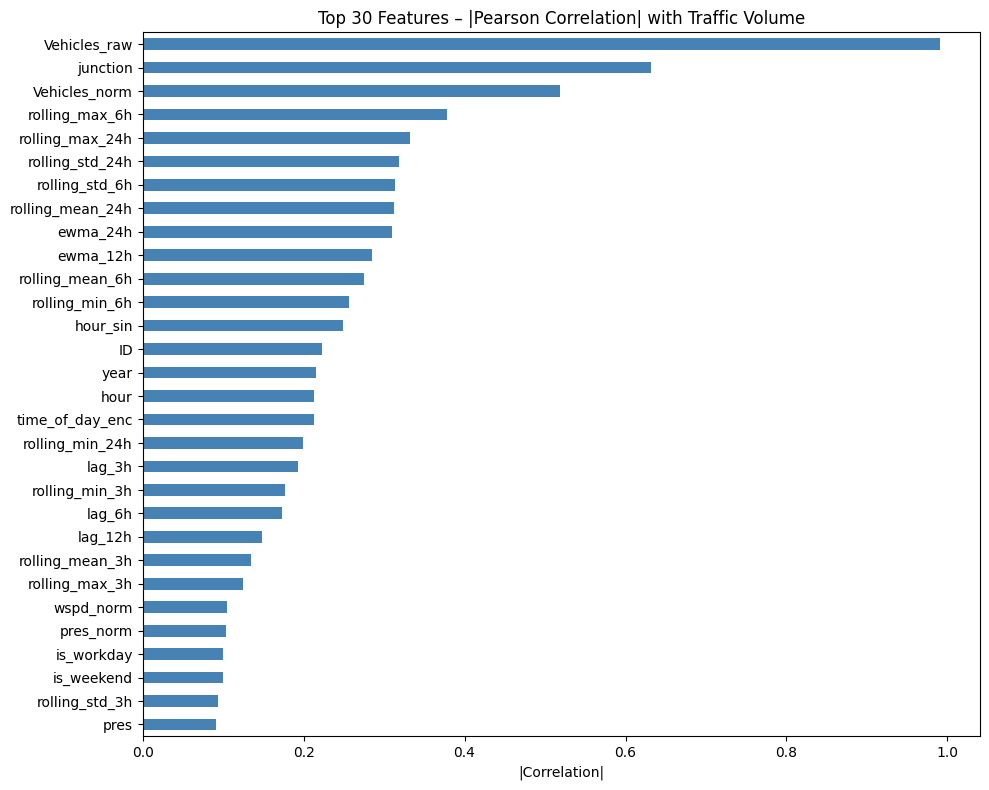

  Saved: correlation_importance.png

  Top-20 features by Random Forest importance:
Vehicles_raw        9.825596e-01
junction            8.573051e-03
Vehicles_norm       8.186385e-03
rolling_max_6h      5.683191e-04
rolling_std_6h      6.732603e-05
wspd_norm           2.793709e-05
lag_2h              2.237226e-06
rolling_min_3h      1.736109e-06
rolling_mean_3h     1.523697e-06
rolling_mean_24h    1.000755e-06
ewma_12h            9.141461e-07
rolling_mean_6h     8.886325e-07
rolling_std_3h      8.142803e-07
lag_12h             7.703544e-07
ID                  7.625863e-07
lag_6h              7.281738e-07
temp_norm           6.533309e-07
lag_168h            5.762090e-07
rolling_max_3h      4.768260e-07
ewma_24h            3.880080e-07


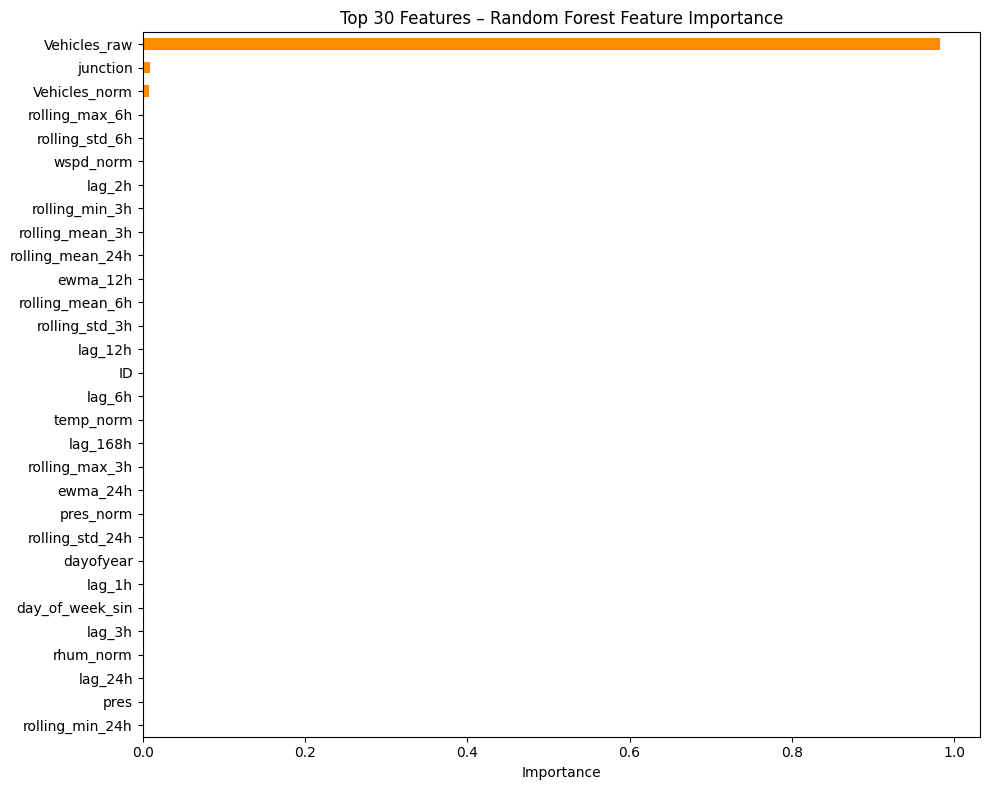

  Saved: rf_importance.png


In [57]:
# ─────────────────────────────────────────────
# 7.  FEATURE IMPORTANCE EVALUATION
# ─────────────────────────────────────────────
print("\n[5] Evaluating feature importance …")
 
# ── 6a. Correlation analysis ──────────────────
num_df = df_fe.select_dtypes(include=[np.number])
if TARGET in num_df.columns:
    corr_with_target = (
        num_df.corr()[TARGET]
              .drop(TARGET)
              .abs()
              .sort_values(ascending=False)
    )
 
    print("\n  Top-20 features by Pearson |correlation| with target:")
    print(corr_with_target.head(20).to_string())
 
    # Plot
    plt.figure(figsize=(10, 8))
    corr_with_target.head(30).plot(kind="barh", color="steelblue")
    plt.title("Top 30 Features – |Pearson Correlation| with Traffic Volume")
    plt.xlabel("|Correlation|")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\correlation_importance.png", dpi=150)
    plt.show()
    plt.close()
    print("  Saved: correlation_importance.png")
 
# ── 6b. Random Forest feature importance ─────
# Build feature matrix X – drop target + non-numeric leftovers
drop_cols = [TARGET, "datetime"] + cat_cols   # drop raw categoricals
X_cols = [c for c in num_df.columns
          if c != TARGET and c in df_fe.columns]
X = df_fe[X_cols].copy()
y = df_fe[TARGET].copy()
 
# Sub-sample for speed (max 50 000 rows)
sample_size = min(50_000, len(X))
idx = np.random.choice(len(X), sample_size, replace=False)
X_s, y_s = X.iloc[idx], y.iloc[idx]
 
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_s, y_s)
 
rf_importance = pd.Series(rf.feature_importances_, index=X_cols).sort_values(ascending=False)
 
print("\n  Top-20 features by Random Forest importance:")
print(rf_importance.head(20).to_string())
 
# Plot
plt.figure(figsize=(10, 8))
rf_importance.head(30).plot(kind="barh", color="darkorange")
plt.title("Top 30 Features – Random Forest Feature Importance")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\correlation_importance.png", dpi=150)
plt.show()
plt.close()
print("  Saved: rf_importance.png")
 
 


[5] Evaluating feature importance …
  Features used (58): leakage columns excluded

  Top-20 features by Pearson |correlation| with target:
junction            0.631525
rolling_max_6h      0.378645
rolling_max_24h     0.332418
rolling_std_24h     0.318468
rolling_std_6h      0.313817
rolling_mean_24h    0.312467
ewma_24h            0.310410
ewma_12h            0.284974
rolling_mean_6h     0.274828
rolling_min_6h      0.256886
hour_sin            0.248913
year                0.215971
hour                0.212852
time_of_day_enc     0.212546
rolling_min_24h     0.199560
lag_3h              0.193294
rolling_min_3h      0.177005
lag_6h              0.172885
lag_12h             0.148768
rolling_mean_3h     0.134171


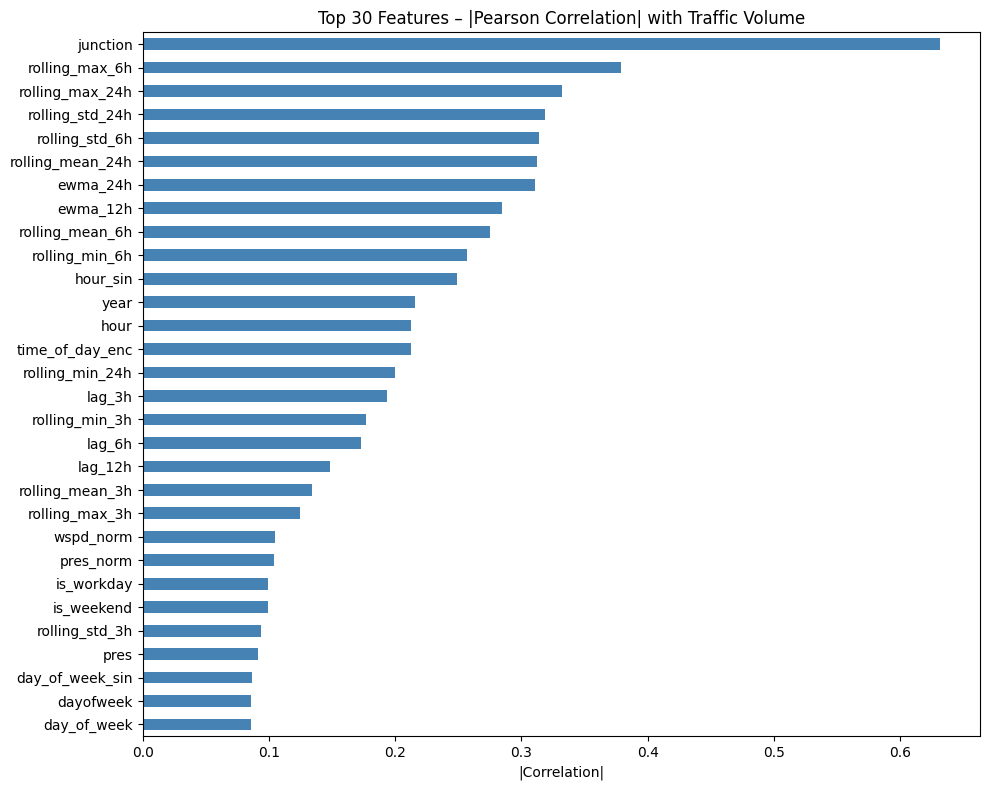

  Saved: correlation_pearson.png

  Top-20 features by Random Forest importance:
         feature  importance
        junction    0.558397
  rolling_max_6h    0.334139
 rolling_mean_6h    0.028904
            year    0.010811
            hour    0.010287
 rolling_max_24h    0.007496
 time_of_day_enc    0.005747
 rolling_std_24h    0.005195
        ewma_12h    0.004393
        ewma_24h    0.003596
        hour_sin    0.003594
        hour_cos    0.002794
  rolling_std_6h    0.002071
            dwpt    0.001171
       dayofyear    0.001130
    day_of_month    0.001128
             day    0.001099
rolling_mean_24h    0.001080
  rolling_max_3h    0.001032
  rolling_min_6h    0.000955


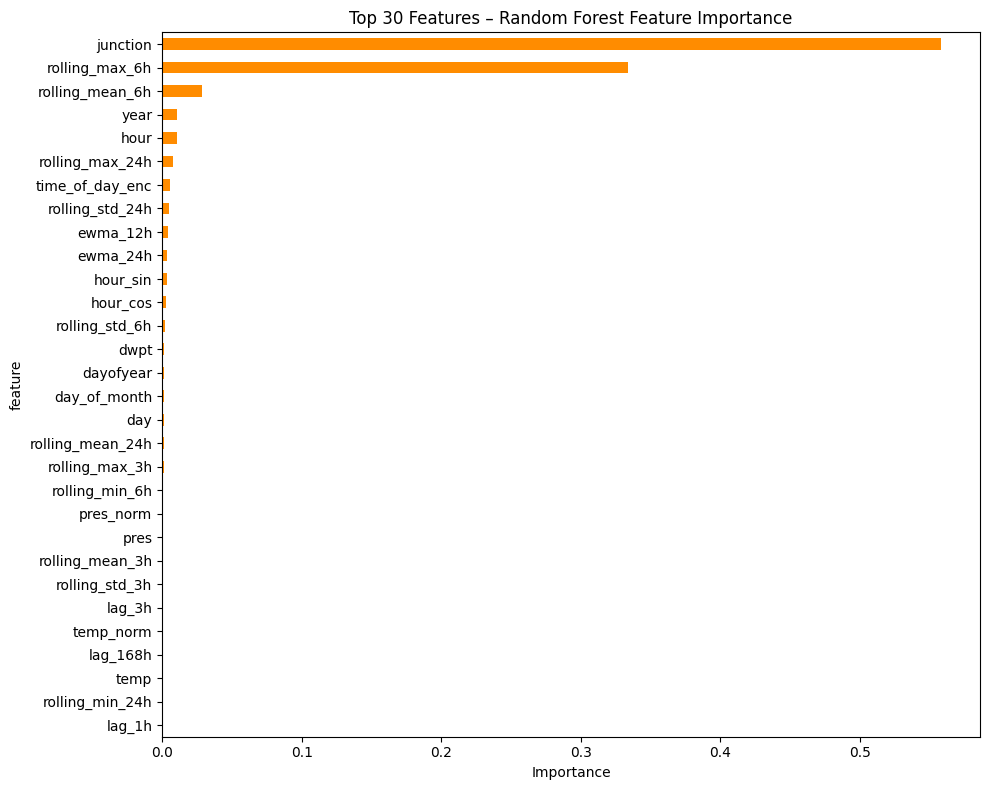

  Saved: rf_importance.png


In [58]:
# ─────────────────────────────────────────────
# 8.  FEATURE IMPORTANCE EVALUATION (LEAKAGE-FREE)
# ─────────────────────────────────────────────
print("\n[5] Evaluating feature importance …")

# ── Drop leakage + non-feature columns ──
leakage_cols = ["Vehicles_raw", "Vehicles_norm", "ID"]
drop_cols    = leakage_cols + [TARGET, "datetime"]

# ── Keep only numeric columns, exclude leakage ──
num_df = df_fe.select_dtypes(include=[np.number])
X_cols = [c for c in num_df.columns if c not in drop_cols]

X = df_fe[X_cols].copy().fillna(0)
y = df_fe[TARGET].copy()

print(f"  Features used ({len(X_cols)}): leakage columns excluded")

# ── 6a. Correlation analysis ──
corr_with_target = (
    num_df[X_cols + [TARGET]].corr()[TARGET]
    .drop(TARGET)
    .abs()
    .sort_values(ascending=False)
)

print("\n  Top-20 features by Pearson |correlation| with target:")
print(corr_with_target.head(20).to_string())

plt.figure(figsize=(10, 8))
corr_with_target.head(30).plot(kind="barh", color="steelblue")
plt.title("Top 30 Features – |Pearson Correlation| with Traffic Volume")
plt.xlabel("|Correlation|")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\correlation_pearson.png", dpi=150)
plt.show()
plt.close()
print("  Saved: correlation_pearson.png")

# ── 6b. Random Forest feature importance ──
sample_size = min(50_000, len(X))
idx  = np.random.choice(len(X), sample_size, replace=False)
X_s  = X.iloc[idx]
y_s  = y.iloc[idx]

rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42
)
rf.fit(X_s, y_s)

importance_df = pd.DataFrame({
    "feature"    : X_cols,
    "importance" : rf.feature_importances_
}).sort_values("importance", ascending=False)

print("\n  Top-20 features by Random Forest importance:")
print(importance_df.head(20).to_string(index=False))

plt.figure(figsize=(10, 8))
importance_df.head(30).set_index("feature")["importance"].plot(kind="barh", color="darkorange")
plt.title("Top 30 Features – Random Forest Feature Importance")
plt.xlabel("Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\rf_importance.png", dpi=150)
plt.show()
plt.close()
print("  Saved: rf_importance.png")


[6] Selecting final feature set …

  Total selected features: 40
  Selected features:
    • day_of_week
    • day_of_week_cos
    • day_of_week_sin
    • dayofyear
    • ewma_12h
    • ewma_24h
    • hour
    • hour_cos
    • hour_sin
    • is_holiday
    • is_rush_hour
    • is_special_event
    • is_weekend
    • is_workday
    • junction
    • lag_12h
    • lag_168h
    • lag_1h
    • lag_24h
    • lag_2h
    • lag_3h
    • lag_6h
    • month
    • pres_norm
    • rolling_max_24h
    • rolling_max_3h
    • rolling_max_6h
    • rolling_mean_24h
    • rolling_mean_3h
    • rolling_mean_6h
    • rolling_min_24h
    • rolling_min_3h
    • rolling_min_6h
    • rolling_std_24h
    • rolling_std_3h
    • rolling_std_6h
    • temp_norm
    • time_of_day_enc
    • wspd_norm
    • year

  Feature ranking by combined score:
                  correlation_importance  rf_importance  combined_score
junction                          0.6315         0.0086          1.0000
rolling_max_6h             

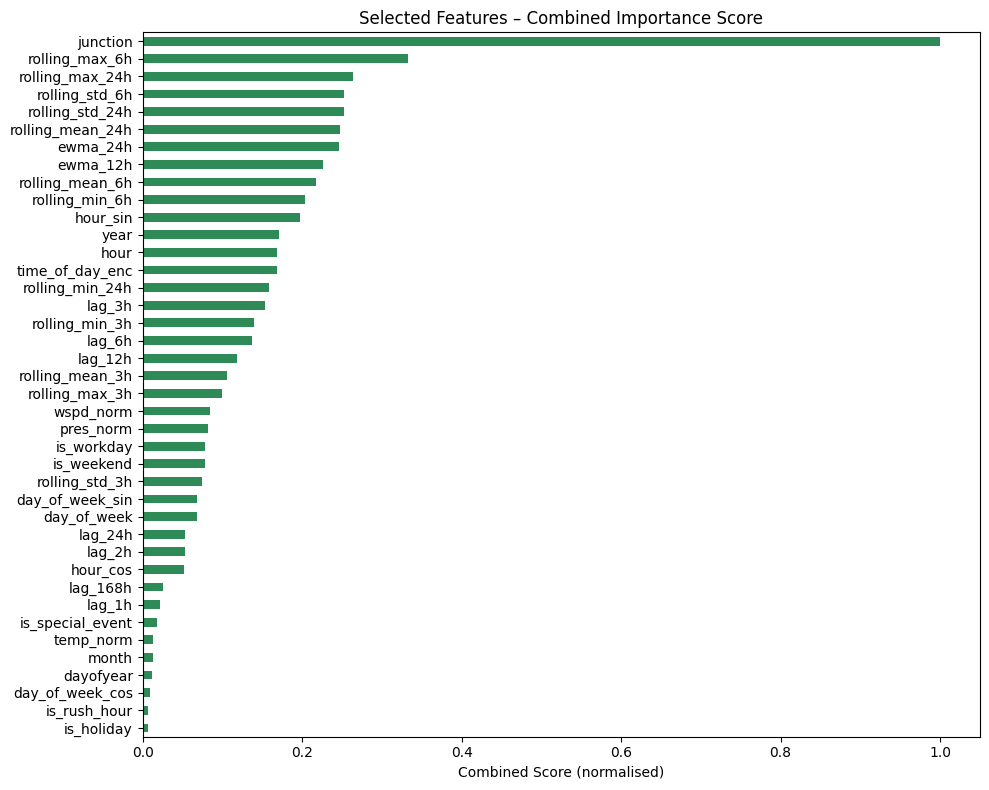

  Saved: combined_importance.png


In [60]:
# ─────────────────────────────────────────────
# 9.  FEATURE SELECTION
# ─────────────────────────────────────────────
print("\n[6] Selecting final feature set …")
 
# Strategy: union of top-N from correlation + top-N from RF importance
TOP_N = 25
 
top_corr_features = set(corr_with_target.head(TOP_N).index)
top_rf_features   = set(rf_importance.head(TOP_N).index)
 
# Always keep essential hand-crafted features
essential = {
    "hour", "day_of_week", "month", "is_weekend",
    "is_holiday", "is_special_event", "is_workday", "is_rush_hour",
    "hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos",
    "lag_1h", "lag_24h", "rolling_mean_3h", "rolling_mean_24h",
    "ewma_12h"
}
 
selected_features = sorted(
    (top_corr_features | top_rf_features | essential) & set(X_cols)
)
 
print(f"\n  Total selected features: {len(selected_features)}")
print("  Selected features:")
for f in selected_features:
    print(f"    • {f}")
 
# ── Combined importance score (normalised average) ────────────────────────
importance_df = pd.DataFrame({
    "correlation_importance": corr_with_target.reindex(selected_features).fillna(0),
    "rf_importance"         : rf_importance.reindex(selected_features).fillna(0),
})
importance_df["correlation_importance_norm"] = (
    importance_df["correlation_importance"] /
    importance_df["correlation_importance"].max()
)
importance_df["rf_importance_norm"] = (
    importance_df["rf_importance"] /
    importance_df["rf_importance"].max()
)
importance_df["combined_score"] = (
    importance_df["correlation_importance_norm"] +
    importance_df["rf_importance_norm"]
) / 2
importance_df = importance_df.sort_values("combined_score", ascending=False)
 
print("\n  Feature ranking by combined score:")
print(importance_df[["correlation_importance","rf_importance","combined_score"]]
      .round(4).to_string())
 
# Plot combined score
plt.figure(figsize=(10, 8))
importance_df["combined_score"].sort_values().plot(kind="barh", color="seagreen")
plt.title("Selected Features – Combined Importance Score")
plt.xlabel("Combined Score (normalised)")
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\combined_importance.png", dpi=150)
plt.show()
plt.close()
print("  Saved: combined_importance.png")
 

In [ ]:
# ─────────────────────────────────────────────
# 9.  SAVE ENGINEERED DATASET
# ─────────────────────────────────────────────
final_cols = selected_features + [TARGET]
df_final = df_fe[final_cols].copy()
df_final.to_csv(r"C:\Users\syin\Downloads\Uber_project\Datasets\engineered_ML_traffic_data.csv", index=False)

print(f"\n✅ Final engineered dataset saved → engineered_ML_traffic_data.csv")
print(f"   Shape : {df_final.shape}")
print(f"   Target: {TARGET}")
print(f"   Features ({len(selected_features)}): {selected_features}")
 
# Save importance table
importance_df.to_csv(r"C:\Users\syin\Downloads\Uber_project\Datasets\feature_importance_report.csv")
print("✅ Feature importance report saved → feature_importance_report.csv")
 


✅ Final engineered dataset saved → engineered_traffic_data.csv
   Shape : (48120, 41)
   Target: Vehicles
   Features (40): ['day_of_week', 'day_of_week_cos', 'day_of_week_sin', 'dayofyear', 'ewma_12h', 'ewma_24h', 'hour', 'hour_cos', 'hour_sin', 'is_holiday', 'is_rush_hour', 'is_special_event', 'is_weekend', 'is_workday', 'junction', 'lag_12h', 'lag_168h', 'lag_1h', 'lag_24h', 'lag_2h', 'lag_3h', 'lag_6h', 'month', 'pres_norm', 'rolling_max_24h', 'rolling_max_3h', 'rolling_max_6h', 'rolling_mean_24h', 'rolling_mean_3h', 'rolling_mean_6h', 'rolling_min_24h', 'rolling_min_3h', 'rolling_min_6h', 'rolling_std_24h', 'rolling_std_3h', 'rolling_std_6h', 'temp_norm', 'time_of_day_enc', 'wspd_norm', 'year']
✅ Feature importance report saved → feature_importance_report.csv


"""
Baseline Models for Traffic Volume Prediction
==============================================
Runs simple, interpretable baselines BEFORE any complex ML.
Models included:
  1. Naive Last-Value         – predict = previous hour's value
  2. Naive Same-Hour-Last-Day – predict = same hour, 24 h ago
  3. Naive Same-Hour-Last-Week– predict = same hour, 168 h ago
  4. Rolling Mean             – rolling 3-hour mean
  5. Linear Regression        – on selected engineered features
  6. Ridge Regression         – regularised linear model
  7. Decision Tree (shallow)  – max_depth=5, human-readable
  8. KNN Regressor            – k=5
Outputs:
  • baseline_comparison.csv       – metric table
  • baseline_comparison.png       – bar chart
  • decision_tree_rules.txt       – readable tree rules
  • actual_vs_predicted.png       – plot for best model
"""

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
 
from sklearn.linear_model    import LinearRegression, Ridge
from sklearn.tree            import DecisionTreeRegressor, export_text
from sklearn.neighbors       import KNeighborsRegressor
from sklearn.preprocessing   import StandardScaler
from sklearn.metrics         import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
 

In [86]:
# ─────────────────────────────────────────────
# 0.  LOAD ENGINEERED DATA
# ─────────────────────────────────────────────
INPUT_FILE = r"C:\Users\syin\Downloads\Uber_project\Datasets\engineered_ML_traffic_data.csv"   # output of feature_engineering_selection.py
TARGET     = "Vehicles"
 
print(f"Loading {INPUT_FILE} …")
df = pd.read_csv(INPUT_FILE)
print(f"  Shape : {df.shape}")
print(f"  Columns: {list(df.columns)}\n")
 
# ─────────────────────────────────────────────
# HELPER: metric bundle
# ─────────────────────────────────────────────
def evaluate(name, y_true, y_pred):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / (y_true + 1e-9))) * 100
    r2   = r2_score(y_true, y_pred)
    print(f"  {name:<35} MAE={mae:8.2f}  RMSE={rmse:8.2f}  MAPE={mape:6.2f}%  R²={r2:.4f}")
    return {"Model": name, "MAE": round(mae,2), "RMSE": round(rmse,2),
            "MAPE(%)": round(mape,2), "R2": round(r2,4)}
 
results = []

Loading C:\Users\syin\Downloads\Uber_project\Datasets\engineered_ML_traffic_data.csv …
  Shape : (48120, 41)
  Columns: ['day_of_week', 'day_of_week_cos', 'day_of_week_sin', 'dayofyear', 'ewma_12h', 'ewma_24h', 'hour', 'hour_cos', 'hour_sin', 'is_holiday', 'is_rush_hour', 'is_special_event', 'is_weekend', 'is_workday', 'junction', 'lag_12h', 'lag_168h', 'lag_1h', 'lag_24h', 'lag_2h', 'lag_3h', 'lag_6h', 'month', 'pres_norm', 'rolling_max_24h', 'rolling_max_3h', 'rolling_max_6h', 'rolling_mean_24h', 'rolling_mean_3h', 'rolling_mean_6h', 'rolling_min_24h', 'rolling_min_3h', 'rolling_min_6h', 'rolling_std_24h', 'rolling_std_3h', 'rolling_std_6h', 'temp_norm', 'time_of_day_enc', 'wspd_norm', 'year', 'Vehicles']



In [87]:
# ─────────────────────────────────────────────
# 1.  NAIVE BASELINES  (no training needed)
# ─────────────────────────────────────────────
print("=" * 65)
print("[1] Naive / Heuristic Baselines")
print("=" * 65)
 
y = df[TARGET].values
 
# 1a. Last value (lag_1h)
if "lag_1h" in df.columns:
    mask = df["lag_1h"].notna()
    results.append(evaluate("Naive – Last Hour (lag_1h)",
                             y[mask], df["lag_1h"].values[mask]))
 
# 1b. Same hour yesterday (lag_24h)
if "lag_24h" in df.columns:
    mask = df["lag_24h"].notna()
    results.append(evaluate("Naive – Same Hour Yesterday (lag_24h)",
                             y[mask], df["lag_24h"].values[mask]))
 
# 1c. Same hour last week (lag_168h if present)
lag_week_col = None
for c in ["lag_168h", "lag_week"]:
    if c in df.columns:
        lag_week_col = c
        break
if lag_week_col:
    mask = df[lag_week_col].notna()
    results.append(evaluate("Naive – Same Hour Last Week",
                             y[mask], df[lag_week_col].values[mask]))
 
# 1d. Rolling 3-hour mean
if "rolling_mean_3h" in df.columns:
    mask = df["rolling_mean_3h"].notna()
    results.append(evaluate("Naive – Rolling Mean (3 h)",
                             y[mask], df["rolling_mean_3h"].values[mask]))
 

[1] Naive / Heuristic Baselines
  Naive – Last Hour (lag_1h)          MAE=   21.23  RMSE=   29.12  MAPE=143.44%  R²=-1.0541
  Naive – Same Hour Yesterday (lag_24h) MAE=   19.24  RMSE=   27.73  MAPE=143.38%  R²=-0.8631
  Naive – Same Hour Last Week         MAE=   19.70  RMSE=   28.22  MAPE=148.31%  R²=-0.9290
  Naive – Rolling Mean (3 h)          MAE=   16.77  RMSE=   22.08  MAPE=115.69%  R²=-0.1806


In [88]:
# ─────────────────────────────────────────────
# 2.  GLOBAL MEAN / MEDIAN
# ─────────────────────────────────────────────
print("\n[2] Statistical Baselines")
print("=" * 65)
 
# Use first 80 % as train, rest as test  (time-ordered)
split_idx = int(len(df) * 0.80)
y_train = y[:split_idx]
y_test  = y[split_idx:]
 
global_mean   = np.full(len(y_test), y_train.mean())
global_median = np.full(len(y_test), np.median(y_train))
results.append(evaluate("Statistical – Global Mean",   y_test, global_mean))
results.append(evaluate("Statistical – Global Median", y_test, global_median))
 


[2] Statistical Baselines
  Statistical – Global Mean           MAE=   18.27  RMSE=   27.13  MAPE=115.35%  R²=-0.0664
  Statistical – Global Median         MAE=   18.37  RMSE=   29.27  MAPE= 82.74%  R²=-0.2417


In [89]:
# ─────────────────────────────────────────────
# 3.  ML BASELINES  (simple, interpretable)
# ─────────────────────────────────────────────
print("\n[3] ML Baselines (TimeSeriesSplit CV)")
print("=" * 65)
 
# Feature set – drop target, use whatever is numeric
feature_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if c != TARGET]
X = df[feature_cols].fillna(0).values
 
X_train, X_test = X[:split_idx], X[split_idx:]
y_train_arr, y_test_arr = y[:split_idx], y[split_idx:]
 
# Scale for linear models
scaler   = StandardScaler()
X_tr_sc  = scaler.fit_transform(X_train)
X_te_sc  = scaler.transform(X_test)
 
# 3a. Linear Regression
lr = LinearRegression()
lr.fit(X_tr_sc, y_train_arr)
results.append(evaluate("Linear Regression", y_test_arr, lr.predict(X_te_sc)))
 
# 3b. Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_tr_sc, y_train_arr)
results.append(evaluate("Ridge Regression (α=1)", y_test_arr, ridge.predict(X_te_sc)))
 
# 3c. Shallow Decision Tree
dt = DecisionTreeRegressor(max_depth=5, min_samples_leaf=20, random_state=42)
dt.fit(X_train, y_train_arr)
results.append(evaluate("Decision Tree (max_depth=5)", y_test_arr, dt.predict(X_test)))
 
# 3d. KNN
knn = KNeighborsRegressor(n_neighbors=5, n_jobs=-1)
knn.fit(X_tr_sc, y_train_arr)
results.append(evaluate("KNN (k=5)", y_test_arr, knn.predict(X_te_sc)))
 


[3] ML Baselines (TimeSeriesSplit CV)
  Linear Regression                   MAE=   10.65  RMSE=   14.48  MAPE= 62.33%  R²=0.6963
  Ridge Regression (α=1)              MAE=   10.65  RMSE=   14.48  MAPE= 62.32%  R²=0.6963
  Decision Tree (max_depth=5)         MAE=    4.79  RMSE=    6.85  MAPE= 27.34%  R²=0.9320
  KNN (k=5)                           MAE=   10.55  RMSE=   16.26  MAPE= 52.81%  R²=0.6168


In [90]:
# ─────────────────────────────────────────────
# 4.  CROSS-VALIDATED LINEAR REGRESSION
# ─────────────────────────────────────────────
print("\n[4] TimeSeriesSplit CV – Linear & Ridge")
print("=" * 65)
 
tscv = TimeSeriesSplit(n_splits=5)
for name, model in [("LinReg CV-5", LinearRegression()),
                    ("Ridge  CV-5", Ridge(alpha=1.0))]:
    maes = []
    for tr_idx, te_idx in tscv.split(X):
        Xtr = scaler.fit_transform(X[tr_idx])
        Xte = scaler.transform(X[te_idx])
        model.fit(Xtr, y[tr_idx])
        maes.append(mean_absolute_error(y[te_idx], model.predict(Xte)))
    print(f"  {name}: Mean MAE = {np.mean(maes):.2f} ± {np.std(maes):.2f}")


[4] TimeSeriesSplit CV – Linear & Ridge
  LinReg CV-5: Mean MAE = 9.01 ± 1.61
  Ridge  CV-5: Mean MAE = 9.01 ± 1.61


In [91]:
# ─────────────────────────────────────────────
# 5.  RESULTS TABLE
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("[5] Baseline Comparison Summary")
print("=" * 65)
 
results_df = pd.DataFrame(results).sort_values("RMSE")
print(results_df.to_string(index=False))
results_df.to_csv(r"C:\Users\syin\Downloads\Uber_project\Datasets\baseline_comparison.csv", index=False)
print("\n  Saved → baseline_comparison.csv")
 


[5] Baseline Comparison Summary
                                Model   MAE  RMSE  MAPE(%)      R2
          Decision Tree (max_depth=5)  4.79  6.85    27.34  0.9320
                    Linear Regression 10.65 14.48    62.33  0.6963
               Ridge Regression (α=1) 10.65 14.48    62.32  0.6963
                            KNN (k=5) 10.55 16.26    52.81  0.6168
           Naive – Rolling Mean (3 h) 16.77 22.08   115.69 -0.1806
            Statistical – Global Mean 18.27 27.13   115.35 -0.0664
Naive – Same Hour Yesterday (lag_24h) 19.24 27.73   143.38 -0.8631
          Naive – Same Hour Last Week 19.70 28.22   148.31 -0.9290
           Naive – Last Hour (lag_1h) 21.23 29.12   143.44 -1.0541
          Statistical – Global Median 18.37 29.27    82.74 -0.2417

  Saved → baseline_comparison.csv



[6] Generating plots …


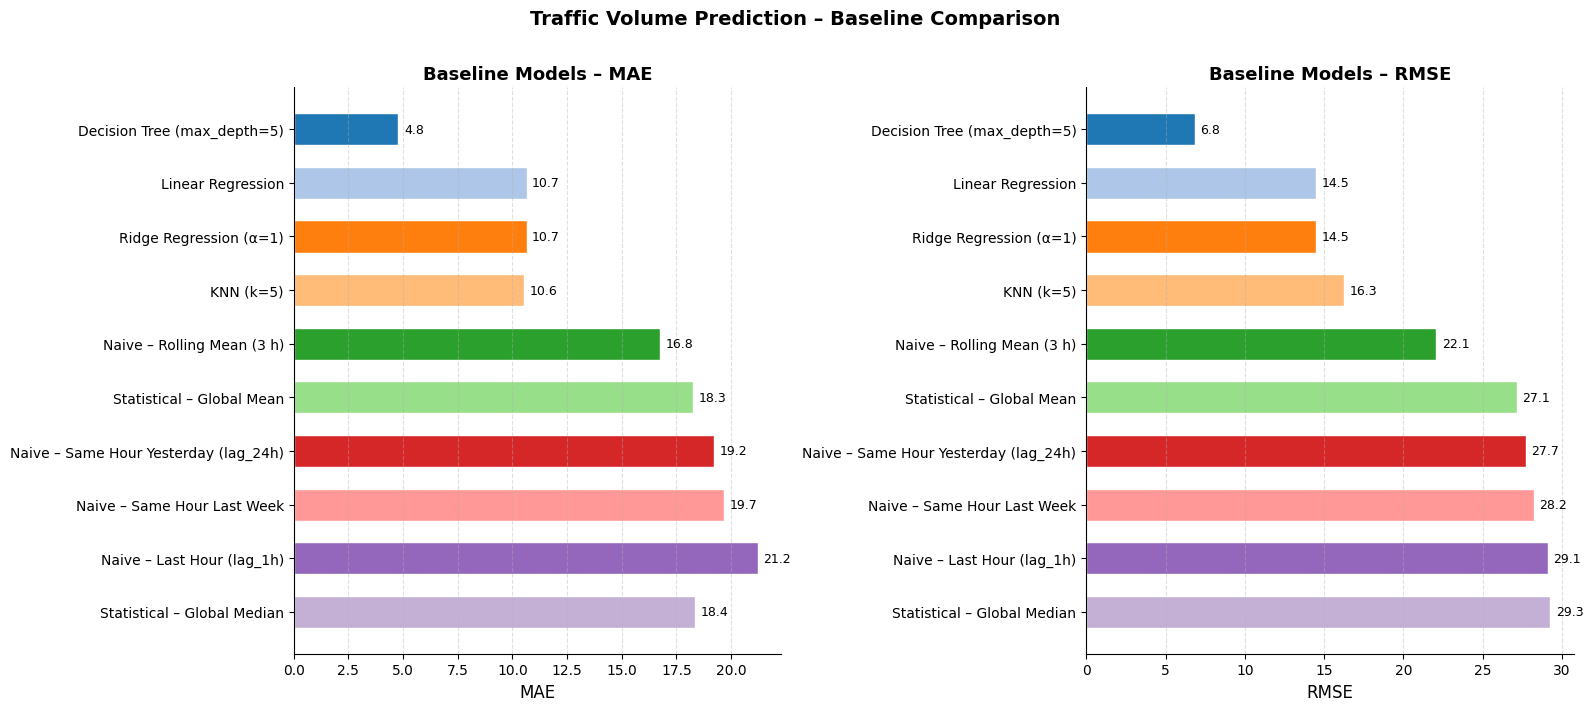

  Saved → baseline_comparison.png


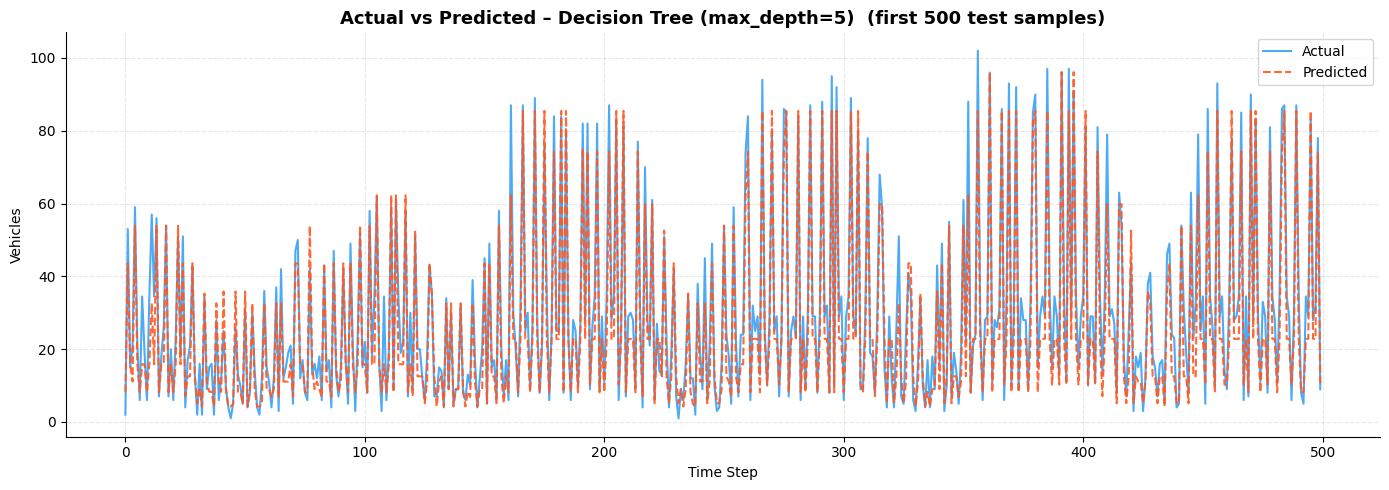

  Saved → actual_vs_predicted.png  (best model: Decision Tree (max_depth=5))


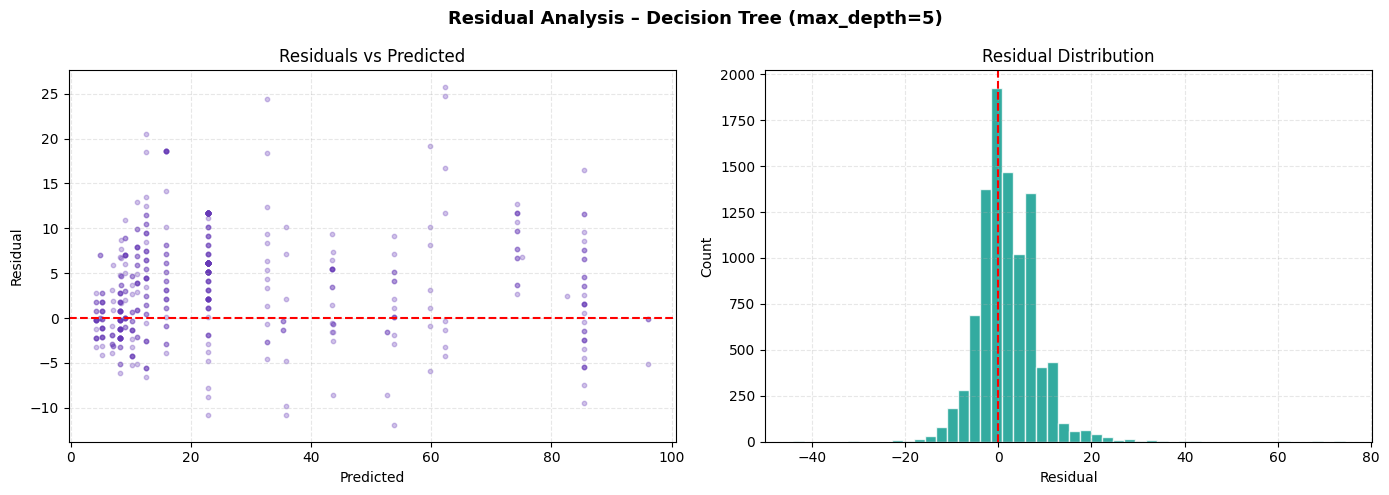

  Saved → residual_analysis.png


In [92]:
# ─────────────────────────────────────────────
# 6.  PLOTS
# ─────────────────────────────────────────────
print("\n[6] Generating plots …")
 
# 6a. Bar chart – MAE & RMSE
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = plt.cm.tab20.colors
 
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    vals   = results_df[metric].values
    labels = results_df["Model"].values
    bars   = ax.barh(labels, vals,
                     color=colors[:len(labels)], edgecolor="white", height=0.6)
    ax.bar_label(bars, fmt="%.1f", padding=4, fontsize=9)
    ax.set_xlabel(metric, fontsize=12)
    ax.set_title(f"Baseline Models – {metric}", fontsize=13, fontweight="bold")
    ax.invert_yaxis()
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top","right"]].set_visible(False)
 
plt.suptitle("Traffic Volume Prediction – Baseline Comparison",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\baseline_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("  Saved → baseline_comparison.png")
 
# 6b. Actual vs Predicted – best ML model (lowest RMSE among ML models)
ml_names = ["Linear Regression","Ridge Regression (α=1)",
            "Decision Tree (max_depth=5)","KNN (k=5)"]
ml_results = results_df[results_df["Model"].isin(ml_names)]
if not ml_results.empty:
    best_name = ml_results.iloc[0]["Model"]
    model_map = {
        "Linear Regression"        : (lr,    X_te_sc),
        "Ridge Regression (α=1)"   : (ridge, X_te_sc),
        "Decision Tree (max_depth=5)": (dt,  X_test),
        "KNN (k=5)"                : (knn,  X_te_sc),
    }
    best_model, best_X = model_map[best_name]
    y_pred_best = best_model.predict(best_X)
 
    plot_n = min(500, len(y_test_arr))
    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(y_test_arr[:plot_n],  label="Actual",    color="#2196F3", lw=1.5, alpha=0.8)
    ax.plot(y_pred_best[:plot_n], label="Predicted", color="#FF5722",
            lw=1.5, linestyle="--", alpha=0.9)
    ax.set_title(f"Actual vs Predicted – {best_name}  (first {plot_n} test samples)",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Time Step"); ax.set_ylabel("Vehicles")
    ax.legend(); ax.grid(linestyle="--", alpha=0.3)
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\actual_vs_predicted.png", dpi=150)
    plt.show()
    plt.close()
    print(f"  Saved → actual_vs_predicted.png  (best model: {best_name})")
 
# 6c. Residual plot for best ML model
if not ml_results.empty:
    residuals = y_test_arr - y_pred_best
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
    axes[0].scatter(y_pred_best[:plot_n], residuals[:plot_n],
                    alpha=0.3, s=10, color="#673AB7")
    axes[0].axhline(0, color="red", lw=1.5, linestyle="--")
    axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Residual")
    axes[0].set_title("Residuals vs Predicted")
    axes[0].grid(linestyle="--", alpha=0.3)
 
    axes[1].hist(residuals, bins=50, color="#009688", edgecolor="white", alpha=0.8)
    axes[1].set_xlabel("Residual"); axes[1].set_ylabel("Count")
    axes[1].set_title("Residual Distribution")
    axes[1].axvline(0, color="red", lw=1.5, linestyle="--")
    axes[1].grid(linestyle="--", alpha=0.3)
 
    plt.suptitle(f"Residual Analysis – {best_name}", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\residual_analysis.png", dpi=150)
    plt.show()
    plt.close()
    print("  Saved → residual_analysis.png")

In [93]:
# ─────────────────────────────────────────────
# 7.  DECISION TREE – HUMAN-READABLE RULES
# ─────────────────────────────────────────────
tree_rules = export_text(dt, feature_names=feature_cols, max_depth=4)
with open(r"C:\Users\syin\Downloads\Uber_project\Datasets\decision_tree_rules.txt", "w") as f:
    f.write("Decision Tree Rules (max_depth=5)\n")
    f.write("=" * 60 + "\n\n")
    f.write(tree_rules)
print("  Saved → decision_tree_rules.txt")
 

  Saved → decision_tree_rules.txt



  Top-20 Linear Regression Coefficients (by |value|):
Feature  Coefficient
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN
    NaN          NaN


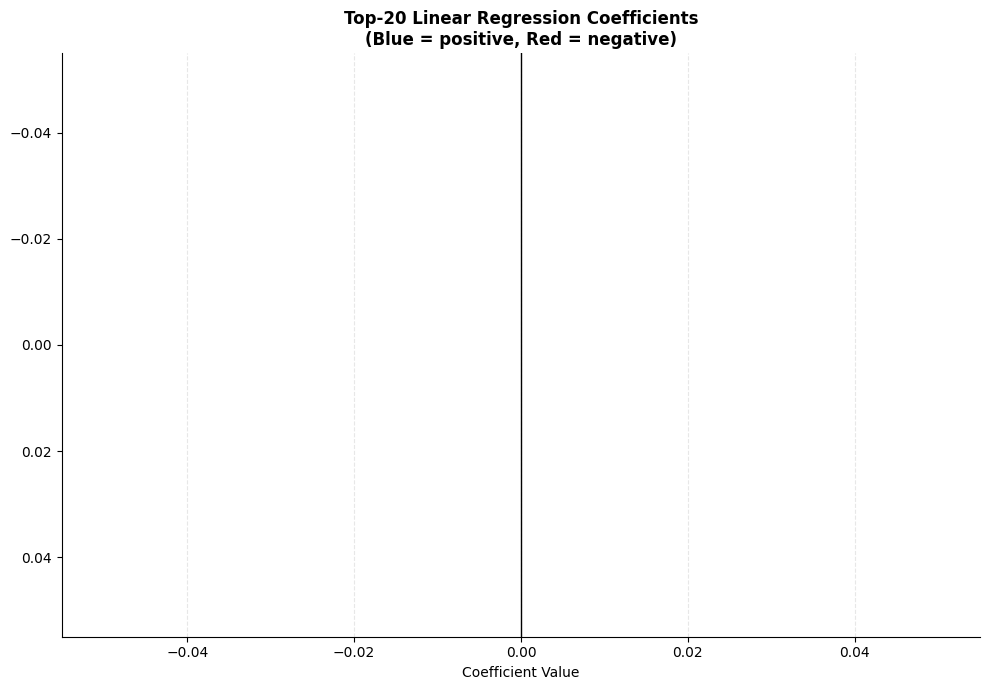

  Saved → lr_coefficients.png


In [94]:
# ─────────────────────────────────────────────
# 8.  LINEAR REGRESSION COEFFICIENTS
# ─────────────────────────────────────────────
coef_df = (pd.DataFrame({"Feature": feature_cols,
                          "Coefficient": lr.coef_})
             .reindex(pd.Series(np.abs(lr.coef_), index=feature_cols)
                       .sort_values(ascending=False).index)
             .head(20))
print("\n  Top-20 Linear Regression Coefficients (by |value|):")
print(coef_df.to_string(index=False))
 
fig, ax = plt.subplots(figsize=(10, 7))
colors_lr = ["#E53935" if v < 0 else "#1E88E5" for v in coef_df["Coefficient"]]
ax.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors_lr, edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.set_title("Top-20 Linear Regression Coefficients\n(Blue = positive, Red = negative)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Coefficient Value")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines[["top","right"]].set_visible(False)
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\lr_coefficients.png", dpi=150)
plt.show()
plt.close()
print("  Saved → lr_coefficients.png")


  Top-20 Linear Regression Coefficients (by |value|):
         Feature  Coefficient
 rolling_mean_3h   -64.608490
          lag_3h    36.220291
          lag_2h    34.920482
          lag_1h    34.352093
  rolling_max_6h    15.823910
        junction   -11.696215
  rolling_std_6h    -7.281404
        ewma_24h     6.472524
  rolling_std_3h    -3.193877
       dayofyear     3.125597
           month    -2.849745
        ewma_12h    -2.419488
        hour_cos    -2.336996
rolling_mean_24h    -2.295205
  rolling_max_3h     2.264523
 rolling_std_24h    -2.029830
 rolling_max_24h     2.026860
            hour     2.001932
 time_of_day_enc     1.979997
        hour_sin    -1.841844


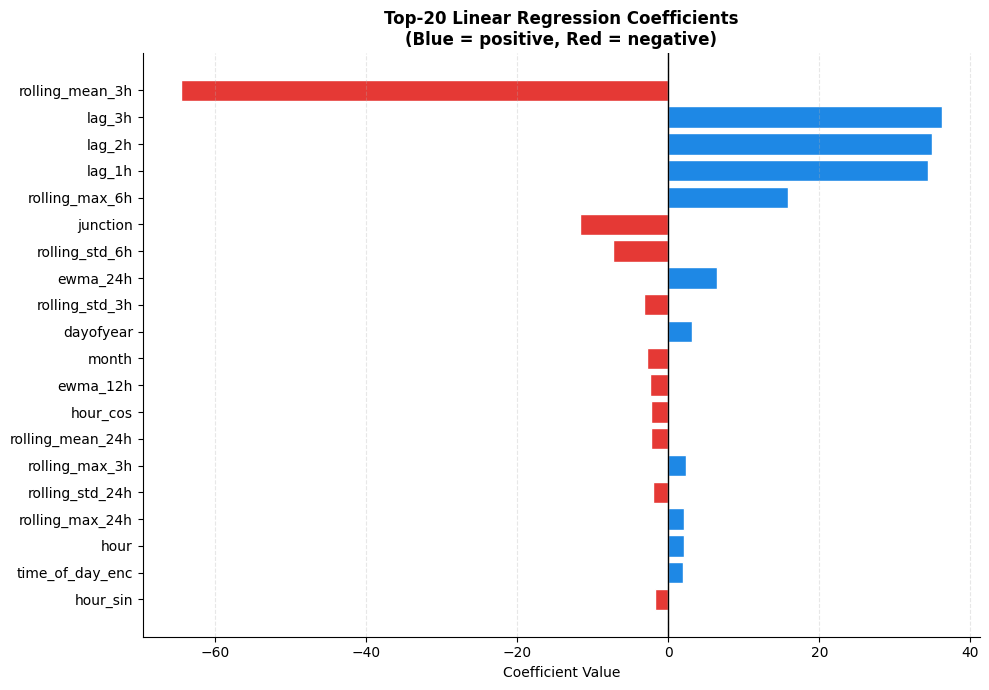

  Saved → lr_coefficients.png


In [97]:
# ── Section 8: Linear Regression Coefficients (FIXED) ──
coef_df = pd.DataFrame({
    "Feature"     : feature_cols,
    "Coefficient" : lr.coef_
})

# Sort by absolute value correctly
coef_df["abs_coef"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values("abs_coef", ascending=False).head(20).drop(columns="abs_coef")
coef_df = coef_df.reset_index(drop=True)

print("\n  Top-20 Linear Regression Coefficients (by |value|):")
print(coef_df.to_string(index=False))

# ── Plot ──
fig, ax = plt.subplots(figsize=(10, 7))
colors_lr = ["#E53935" if v < 0 else "#1E88E5" for v in coef_df["Coefficient"]]
ax.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors_lr, edgecolor="white")
ax.axvline(0, color="black", lw=1)
ax.set_title("Top-20 Linear Regression Coefficients\n(Blue = positive, Red = negative)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Coefficient Value")
ax.invert_yaxis()
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(r"C:\Users\syin\Downloads\Uber_project\Datasets\lr_coefficients.png", dpi=150)
plt.show()
plt.close()
print("  Saved → lr_coefficients.png")

In [98]:
# ─────────────────────────────────────────────
# 9.  FINAL SUMMARY
# ─────────────────────────────────────────────
print("\n" + "=" * 65)
print("✅  BASELINE MODELLING COMPLETE")
print("=" * 65)
best_overall = results_df.iloc[0]
print(f"\n  Best baseline : {best_overall['Model']}")
print(f"    MAE    = {best_overall['MAE']}")
print(f"    RMSE   = {best_overall['RMSE']}")
print(f"    MAPE   = {best_overall['MAPE(%)']}%")
print(f"    R²     = {best_overall['R2']}")
print("""
  Outputs saved:
    baseline_comparison.csv
    baseline_comparison.png
    actual_vs_predicted.png
    residual_analysis.png
    decision_tree_rules.txt
    lr_coefficients.png
 
  Next step → advanced ML models (Random Forest, XGBoost, LSTM …)
""")
 


✅  BASELINE MODELLING COMPLETE

  Best baseline : Decision Tree (max_depth=5)
    MAE    = 4.79
    RMSE   = 6.85
    MAPE   = 27.34%
    R²     = 0.932

  Outputs saved:
    baseline_comparison.csv
    baseline_comparison.png
    actual_vs_predicted.png
    residual_analysis.png
    decision_tree_rules.txt
    lr_coefficients.png
 
  Next step → advanced ML models (Random Forest, XGBoost, LSTM …)

